# Developed Markets Equity Scorecard
## Relative-performance ranking for five developed equity markets over a 3–6 month horizon

### Research objective
Rank the **US, Eurozone, UK, Switzerland and Japan** by expected *relative* equity performance over the next three to six months, and convert that ranking into an allocation view.

### Executive summary
| | |
|---|---|
| **Horizon** | 3 and 6 months, relative to the five-market average |
| **Panel** | Monthly, Dec-2005 → Apr-2026, latest month in which all five markets report |
| **Predictive pillars** | Macro (financial-conditions impulse) and Micro (earnings-revision persistence) |
| **Diagnostic pillars** | Valuation (earnings-yield spread) and Technical (signed trend quality) — retained and shown, zero predictive weight |
| **Key research result** | Replacing the 6-month EPS *revision* with a 12-month *persistence* measure raises the 6M examined-window rank IC from +0.04 to +0.20 on a matched sample |
| **Timing control** | Every signal is lagged one month before being matched to forward returns |
| **Honest limit** | No pillar is statistically significant once the research history is accounted for; the examined window is not untouched holdout data |

### Notebook structure
1. Objective and summary · 2. Data loading and dictionary · 3. Data quality and validation · 4. Signal construction · 5. Macro research · 6. Micro research · 7. Valuation and Technical diagnostics · 8. Predictive-power assessment · 9. Model comparison · 10. Scorecard · 11. Backtest · 12. Current ranking · 13. Conclusions and limitations

**Environment:** Python 3.13, pandas 3.0, numpy 2.5, scipy 1.18, statsmodels 0.15, scikit-learn 1.9, matplotlib 3.11, openpyxl 3.1 (see `requirements.txt`). Run top to bottom with the six supplied workbooks in `data/raw/`. Expected run time: under a minute.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata
from sklearn.linear_model import Ridge
from IPython.display import display
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 240; pd.options.display.max_columns = 40; pd.options.display.max_rows = 250
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10, 'figure.facecolor': 'white'})

ROOT = Path('..').resolve()
OUT = ROOT / 'output' / 'final'
CH = OUT / 'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

MARKETS = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
PILLARS = ['Macro', 'Micro', 'Valuation', 'Technical']
MKT_COLOUR = {'US': '#1f4e79', 'Eurozone': '#2e8b57', 'UK': '#c0504d', 'Switzerland': '#e69f00', 'Japan': '#6a5acd'}
PILLAR_COLOUR = {'Macro': '#1f4e79', 'Micro': '#2e8b57', 'Valuation': '#e69f00', 'Technical': '#7f6aa8'}
SEED = 7
N_BOOTSTRAP = 2000
SIGNAL_LAG = 1          # months between forming a score and holding the position it implies
DISCOVERY_END = pd.Period('2016-12', 'M')
EXAMINED_START = pd.Period('2017-07', 'M')   # six-month embargo after the discovery window
FIGURES = {}            # every number quoted in the deck is recorded here

## 2. Data loading and data dictionary
Five country workbooks plus one combined price workbook. One observation per market per month: the **last** dated observation in each calendar month.

In [2]:
SOURCE_FIELDS = {
    'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   yld='USGGT02Y Index', oas='LF98OAS Index',  pmi='NAPMPMI Index',  fx=None),
    'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  yld='GDBR2 Index',    oas='LECPOAS Index', pmi='MPMIEZMA Index', fx=('EURUSD BGN Curncy', 'direct')),
    'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), yld='GUKG2 Index',    oas='LC61OAS Index', pmi='MPMIGBMA Index', fx=('GBPUSD BGN Curncy', 'direct')),
    'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), yld='GSWISS02 Index', oas='LECPOAS Index', pmi='CH_PMI',         fx=('USDCHF Curncy', 'invert')),
    'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), yld='GJGB2 Index',    oas='LJC1OAS Index', pmi='JPYPMI',         fx=('USDJPY BGN Curncy', 'invert')),
}

def to_month_end_panel(frame):
    """Collapse a raw workbook to one row per calendar month, keeping the last dated observation."""
    d = frame.dropna(subset=['Date']).copy()
    d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    d['_date'] = pd.to_datetime(d['Date'])
    return d.sort_values('_date').drop_duplicates('month', keep='last').set_index('month')

RAW = {m: to_month_end_panel(pd.read_excel(ROOT / 'data' / 'raw' / SOURCE_FIELDS[m]['file'])) for m in MARKETS}

def series(market, key):
    """Return one oriented series for a market. FCI is sign-flipped so that higher always means EASIER."""
    spec = SOURCE_FIELDS[market]; d = RAW[market]
    if key == 'fci':
        return spec['fci'][1] * d[spec['fci'][0]]
    if key == 'fx':
        if spec['fx'] is None:
            return pd.Series(1.0, index=d.index)
        return d[spec['fx'][0]] if spec['fx'][1] == 'direct' else 1.0 / d[spec['fx'][0]]
    return d[{'pe': 'BEst P/E Ratio', 'eps': spec['eps'], 'yld': spec['yld'], 'oas': spec['oas'], 'pmi': spec['pmi']}[key]]

PANEL_INDEX = pd.period_range(max(series(m, 'pe').first_valid_index() for m in MARKETS),
                              min(RAW[m].index.max() for m in MARKETS), freq='M')
PE, EPS, FCI, YLD, OAS, PMI, FX = [pd.DataFrame({m: series(m, k) for m in MARKETS}).reindex(PANEL_INDEX)
                                   for k in ('pe', 'eps', 'fci', 'yld', 'oas', 'pmi', 'fx')]
PRICE_LOCAL = PE * EPS                 # reconstructed index level, local currency (see §3)
PRICE_USD = PRICE_LOCAL * FX
AS_OF = PANEL_INDEX[-1]
FIGURES['as_of'] = str(AS_OF); FIGURES['panel_start'] = str(PANEL_INDEX[0]); FIGURES['panel_months'] = len(PANEL_INDEX)

MEANING = {
    'BEst P/E Ratio': ('Consensus 12-month forward price/earnings ratio', 'ratio', 'Valuation'),
    'Monthly_EPS': ('12-month forward consensus earnings per share (US field)', 'index points', 'Earnings'),
    'BEst EPS': ('12-month forward consensus earnings per share', 'local index points', 'Earnings'),
    'GSFCI Index': ('US financial conditions index, higher = tighter', 'index, 100 = neutral', 'Financial conditions'),
    'GSGBFCI Index': ('UK financial conditions index, higher = tighter', 'index, 100 = neutral', 'Financial conditions'),
    'GSEAFCI Index': ('Euro-area financial conditions index, higher = tighter', 'index, 100 = neutral', 'Financial conditions'),
    'GSJPFCI Index': ('Japan financial conditions index, higher = tighter', 'index, 100 = neutral', 'Financial conditions'),
    'BFCIEU Index': ('Euro-area financial conditions index, higher = easier', 'z-score vs own history', 'Financial conditions'),
    'NAPMPMI Index': ('US manufacturing PMI', 'diffusion index, 50 = unchanged', 'Activity'),
    'MPMIEZMA Index': ('Eurozone manufacturing PMI', 'diffusion index', 'Activity'),
    'MPMIGBMA Index': ('UK manufacturing PMI', 'diffusion index', 'Activity'),
    'CH_PMI': ('Switzerland manufacturing PMI', 'diffusion index', 'Activity'),
    'JPYPMI': ('Japan manufacturing PMI', 'diffusion index', 'Activity'),
    'USGGT02Y Index': ('US 2-year government yield', '% p.a.', 'Rates'),
    'GDBR2 Index': ('German 2-year government yield', '% p.a.', 'Rates'),
    'GUKG2 Index': ('UK 2-year government yield', '% p.a.', 'Rates'),
    'GSWISS02 Index': ('Swiss 2-year government yield', '% p.a.', 'Rates'),
    'GJGB2 Index': ('Japan 2-year government yield', '% p.a.', 'Rates'),
    'LF98OAS Index': ('US high-yield corporate option-adjusted spread', '%', 'Credit'),
    'LECPOAS Index': ('Euro investment-grade corporate option-adjusted spread', '%', 'Credit'),
    'LC61OAS Index': ('Sterling investment-grade corporate option-adjusted spread', '%', 'Credit'),
    'LJC1OAS Index': ('Yen investment-grade corporate option-adjusted spread', '%', 'Credit'),
    'DXY Index': ('Trade-weighted US dollar index', 'index', 'FX'),
    'EURUSD BGN Curncy': ('US dollars per euro', 'rate', 'FX'),
    'GBPUSD BGN Curncy': ('US dollars per pound', 'rate', 'FX'),
    'USDCHF Curncy': ('Swiss francs per US dollar', 'rate', 'FX'),
    'EURCHF Curncy': ('Swiss francs per euro', 'rate', 'FX'),
    'USDJPY BGN Curncy': ('Yen per US dollar', 'rate', 'FX'),
    'VIX Index': ('US equity implied volatility — a single global series', 'index', 'Volatility'),
    'V2X Index': ('Euro-area equity implied volatility', 'index', 'Volatility'),
    'CO1 Comdty': ('Brent crude front-month — a single global series', 'USD/barrel', 'Commodity'),
    'CL1 Comdty (YEN)': ('WTI crude front-month priced in yen', 'JPY/barrel', 'Commodity'),
}
PUBLICATION_LAG = {'Activity': 'Released early in the following month; a 1-month lag applies',
                   'Earnings': 'Live consensus; vintage not verifiable from the workbook',
                   'Valuation': 'Live consensus; vintage not verifiable from the workbook',
                   'Financial conditions': 'Daily market data, available same day',
                   'Rates': 'Market data, available same day', 'Credit': 'Market data, available same day',
                   'FX': 'Market data, available same day', 'Volatility': 'Market data, available same day',
                   'Commodity': 'Market data, available same day'}

rows = []
for m, d in RAW.items():
    for col in [c for c in d.columns if c not in ('Date', '_date', 'month')]:
        s = d[col].dropna()
        if s.empty: continue
        first, last = d[col].first_valid_index(), d[col].last_valid_index()
        meaning, unit, family = MEANING.get(col, ('Not mapped', '', 'Other'))
        rows.append({'market': m, 'field': col, 'meaning': meaning, 'units': unit, 'family': family,
                     'frequency': 'Monthly (last observation in month)', 'first_month': str(first), 'last_month': str(last),
                     'n_months': len(s), 'internal_gaps': int(d[col].loc[first:last].isna().sum()),
                     'distinct_values': s.nunique(), 'share_months_unchanged': round(float((s.diff() == 0).mean()), 3),
                     'publication_timing': PUBLICATION_LAG[family]})
DATA_DICTIONARY = pd.DataFrame(rows)
display(DATA_DICTIONARY.set_index(['market', 'field']).head(20))
DATA_DICTIONARY.to_csv(OUT / 'data_dictionary.csv', index=False)
print(f'{len(DATA_DICTIONARY)} series documented across {len(RAW)} workbooks.')
print(f'Common panel: {PANEL_INDEX[0]} to {AS_OF} ({len(PANEL_INDEX)} months).')
print(f'Missing values in the fields used downstream: {int(pd.concat([PE, EPS, FCI, YLD, FX], axis=1).isna().sum().sum())}')

meaning                            units                family                            frequency first_month last_month  n_months  internal_gaps  distinct_values  \
market   field                                                                                                                                                                                                                               
US       BEst P/E Ratio       Consensus 12-month forward price/earnings ratio                            ratio             Valuation  Monthly (last observation in month)     2005-01    2026-04       256              0              256   
         Monthly_EPS        12-month forward consensus earnings per share ...                     index points              Earnings  Monthly (last observation in month)     2005-01    2026-04       256              0              256   
         DXY Index                             Trade-weighted US dollar index                            index                    FX  Monthly (last observation in month)     2005-01    2026-04       256              0              255   
         LF98OAS Index         US high-yield corporate option-adjusted spread                                %                Credit  Monthly (last observation in month)     2005-01    2026-04       256              0              202   
         CO1 Comdty          Brent crude front-month — a single global series                       USD/barrel             Commodity  Monthly (last observation in month)     2005-01    2026-04       256              0              251   
         VIX Index          US equity implied volatility — a single global...                            index            Volatility  Monthly (last observation in month)     2005-01    2026-04       256              0              242   
         USGGT02Y Index                            US 2-year government yield                           % p.a.                 Rates  Monthly (last observation in month)     2005-01    2026-04       256              0              254   
         NAPMPMI Index                                   US manufacturing PMI  diffusion index, 50 = unchanged              Activity  Monthly (last observation in month)     2005-01    2026-04       256              0              130   
         GSFCI Index          US financial conditions index, higher = tighter             index, 100 = neutral  Financial conditions  Monthly (last observation in month)     2005-01    2026-04       256              0              165   
Eurozone BEst P/E Ratio       Consensus 12-month forward price/earnings ratio                            ratio             Valuation  Monthly (last observation in month)     2005-12    2026-06       247              0              246   
         BEst EPS               12-month forward consensus earnings per share               local index points              Earnings  Monthly (last observation in month)     2005-12    2026-06       247              0              245   
         EURUSD BGN Curncy                                US dollars per euro                             rate                    FX  Monthly (last observation in month)     1996-07    2026-06       360              0              348   
         MPMIEZMA Index                            Eurozone manufacturing PMI                  diffusion index              Activity  Monthly (last observation in month)     1997-06    2026-06       349              0              138   
         GDBR2 Index                           German 2-year government yield                           % p.a.                 Rates  Monthly (last observation in month)     1996-07    2026-06       360              0              339   
         V2X Index                        Euro-area equity implied volatility                            index            Volatility  Monthly (last observation in month)     1999-01    2026-06       330              0              328   
         BFCIEU Index   

46 series documented across 5 workbooks.
Common panel: 2005-12 to 2026-04 (245 months).
Missing values in the fields used downstream: 0


## 3. Data quality and validation
Five findings from the audit change what can and cannot be built. I record them here because they constrain the Technical pillar and the return target.

In [3]:
quality = []

# 3.1 The combined price workbook does not contain index levels
price_book = pd.read_excel(ROOT / 'data' / 'raw' / 'Price_data_all_countries.xlsx')
rows = []
for date_col, value_col in [('US', 'SPX Index'), ('Eurozone ', 'MXEM Index'), ('UK', 'MXGB Index'),
                            ('Switzerland', 'MXCH Index'), ('Japan', 'MXJP Index')]:
    market = date_col.strip()
    s = price_book[[date_col, value_col]].dropna()
    s.index = pd.to_datetime(s[date_col]).dt.to_period('M')
    s = s[~s.index.duplicated(keep='last')][value_col]
    joined = pd.concat([s.rename('book'), PE[market].rename('pe')], axis=1).dropna()
    rows.append({'market': market, 'labelled_ticker': value_col, 'value_range': f'{s.min():.1f} – {s.max():.1f}',
                 'plausible_index_level': 'No', 'median_abs_diff_vs_forward_PE': round(float((joined.book - joined.pe).abs().median()), 4),
                 'max_abs_diff_vs_forward_PE': round(float((joined.book - joined.pe).abs().max()), 4)})
PRICE_BOOK_CHECK = pd.DataFrame(rows).set_index('market')
display(PRICE_BOOK_CHECK)
quality.append({'finding': 'Combined price workbook holds valuation ratios, not index levels',
                'evidence': 'All five columns range 8–39 and track each workbook\'s forward P/E to a median difference of ~0.00; a genuine US index level would be in the thousands',
                'consequence': 'No observed index price exists. Prices must be reconstructed, and the Technical pillar cannot be independent of Valuation and Micro'})

# 3.2 Reconstructed price: identity, and validation against a published index
RETURN_LOCAL = PRICE_LOCAL.pct_change()
published_sp500 = {'2008-09': -9.08, '2008-10': -16.94, '2009-02': -10.99, '2011-09': -7.18,
                   '2018-12': -9.18, '2020-03': -12.51, '2020-04': 12.68, '2022-04': -8.80}
check = pd.DataFrame([{'month': k, 'reconstructed_US_%': RETURN_LOCAL['US'].loc[pd.Period(k, 'M')] * 100,
                       'published_index_%': v} for k, v in published_sp500.items()]).set_index('month')
check['difference_pp'] = check['reconstructed_US_%'] - check['published_index_%']
display(check.round(2))
FIGURES['reconstruction_mad_pp'] = float(check['difference_pp'].abs().mean())
print(f"Mean absolute difference against the published US index: {FIGURES['reconstruction_mad_pp']:.3f} pp over {len(check)} months.")
print('Reconstructed annualised volatility: ' + ', '.join(f'{m} {RETURN_LOCAL[m].std() * np.sqrt(12):.1%}' for m in MARKETS))
quality.append({'finding': 'Reconstructed price is an identity, validated for one market only',
                'evidence': f"P = forward P/E x forward EPS, since P/E = P/EPS. The US series matches published monthly index returns to {FIGURES['reconstruction_mad_pp']:.3f} pp",
                'consequence': 'The other four reconstructions cannot be validated against a published index with the supplied data'})

# 3.3 Price decomposition: what a technical signal is actually made of
decomp = []
for k in (1, 3, 6, 12):
    d_mult = np.log(PE / PE.shift(k)); d_earn = np.log(EPS / EPS.shift(k)); d_total = np.log(PRICE_LOCAL / PRICE_LOCAL.shift(k))
    stacked = pd.concat([d_mult.stack().rename('mult'), d_earn.stack().rename('earn'), d_total.stack().rename('tot')], axis=1).dropna()
    decomp.append({'horizon': f'{k}M', 'identity_error': float((d_total - (d_mult + d_earn)).abs().max().max()),
                   'variance_share_PE_leg': stacked.mult.cov(stacked.tot) / stacked.tot.var(),
                   'variance_share_EPS_leg': stacked.earn.cov(stacked.tot) / stacked.tot.var(),
                   'corr_between_legs': stacked.mult.corr(stacked.earn)})
PRICE_DECOMPOSITION = pd.DataFrame(decomp).set_index('horizon')
display(PRICE_DECOMPOSITION.round(3))
print('Price change decomposes exactly into a multiple leg and an earnings leg. The two offset each other at every horizon.')
quality.append({'finding': 'Technical signals are a function of Valuation and Micro inputs',
                'evidence': 'log(P_t/P_t-k) = log(PE_t/PE_t-k) + log(EPS_t/EPS_t-k), exact to machine precision',
                'consequence': 'The Technical pillar is reported as a diagnostic. No claim of independent information is made'})

# 3.4 Series that are shared across workbooks carry no cross-sectional information
vix_check = pd.DataFrame({m: RAW[m]['VIX Index'] for m in MARKETS if 'VIX Index' in RAW[m].columns}).dropna()
shared = pd.DataFrame([
    {'series': 'VIX Index', 'comparison': 'Switzerland vs US', 'max_abs_difference': float((vix_check['Switzerland'] - vix_check['US']).abs().max()), 'correlation': float(vix_check['Switzerland'].corr(vix_check['US']))},
    {'series': 'VIX Index', 'comparison': 'Japan vs US', 'max_abs_difference': float((vix_check['Japan'] - vix_check['US']).abs().max()), 'correlation': float(vix_check['Japan'].corr(vix_check['US']))},
    {'series': 'VIX Index', 'comparison': 'UK column vs US', 'max_abs_difference': float((vix_check['UK'] - vix_check['US']).abs().max()), 'correlation': float(vix_check['UK'].corr(vix_check['US']))},
    {'series': 'Credit spread', 'comparison': 'Switzerland vs Eurozone', 'max_abs_difference': float((OAS['Switzerland'] - OAS['Eurozone']).abs().max()), 'correlation': float(OAS['Switzerland'].corr(OAS['Eurozone']))},
]).set_index(['series', 'comparison'])
display(shared.round(3))
stress = pd.DataFrame({'UK workbook volatility column': RAW['UK']['VIX Index'], 'US workbook volatility column': RAW['US']['VIX Index']}
                      ).loc[['2008-10', '2020-03']]
display(stress.round(2))
quality.append({'finding': 'The volatility column in the UK workbook is not an equity volatility index',
                'evidence': f"Correlation {float(vix_check['UK'].corr(vix_check['US'])):.2f} with the identical series in the other workbooks, and no spike in Oct-2008 or Mar-2020",
                'consequence': 'Excluded from all signal construction. It cannot be identified from the workbook'})
quality.append({'finding': 'Volatility and oil are single global series repeated across workbooks; Switzerland shares the euro-area credit spread and financial-conditions index',
                'evidence': 'Maximum absolute difference of 0.00 between the US, Swiss and Japanese volatility columns and between the Swiss and euro-area credit spreads',
                'consequence': 'These carry no cross-sectional information for a five-market ranking and are not used as country signals'})

DATA_QUALITY = pd.DataFrame(quality)
display(DATA_QUALITY)
DATA_QUALITY.to_csv(OUT / 'data_quality_findings.csv', index=False)

,labelled_ticker,value_range,plausible_index_level,median_abs_diff_vs_forward_PE,max_abs_diff_vs_forward_PE
market,,,,,
US,SPX Index,10.5 – 24.8,No,0.004,0.055
Eurozone,MXEM Index,8.0 – 18.3,No,0.000,0.019
UK,MXGB Index,7.7 – 16.1,No,0.000,0.005
Switzerland,MXCH Index,10.4 – 20.4,No,0.000,0.010
Japan,MXJP Index,11.1 – 39.2,No,0.000,0.190


,reconstructed_US_%,published_index_%,difference_pp
month,,,
2008-09,-9.090,-9.080,-0.010
2008-10,-16.970,-16.940,-0.030
2009-02,-11.000,-10.990,-0.010
2011-09,-7.170,-7.180,0.010
2018-12,-9.350,-9.180,-0.170
2020-03,-12.530,-12.510,-0.020
2020-04,12.700,12.680,0.020
2022-04,-8.830,-8.800,-0.030


Mean absolute difference against the published US index: 0.039 pp over 8 months.
Reconstructed annualised volatility: US 15.2%, Eurozone 16.5%, UK 13.1%, Switzerland 12.5%, Japan 17.2%


,identity_error,variance_share_PE_leg,variance_share_EPS_leg,corr_between_legs
horizon,,,,
1M,0.000,0.874,0.126,-0.484
3M,0.000,0.660,0.340,-0.588
6M,0.000,0.477,0.523,-0.611
12M,0.000,0.327,0.673,-0.590


Price change decomposes exactly into a multiple leg and an earnings leg. The two offset each other at every horizon.


max_abs_difference  correlation
series        comparison                                              
VIX Index     Switzerland vs US                     0.000        1.000
              Japan vs US                           0.000        1.000
              UK column vs US                      44.590        0.038
Credit spread Switzerland vs Eurozone               0.000        1.000

,UK workbook volatility column,US workbook volatility column
month,,
2008-10,15.300,59.890
2020-03,25.090,53.540


,finding,evidence,consequence
0,Combined price workbook holds valuation ratios...,All five columns range 8–39 and track each wor...,No observed index price exists. Prices must be...
1,"Reconstructed price is an identity, validated ...","P = forward P/E x forward EPS, since P/E = P/E...",The other four reconstructions cannot be valid...
2,Technical signals are a function of Valuation ...,log(P_t/P_t-k) = log(PE_t/PE_t-k) + log(EPS_t/...,The Technical pillar is reported as a diagnost...
3,The volatility column in the UK workbook is no...,Correlation 0.04 with the identical series in ...,Excluded from all signal construction. It cann...
4,Volatility and oil are single global series re...,Maximum absolute difference of 0.00 between th...,These carry no cross-sectional information for...


### Return target
Returns are **price returns in US dollars**, measured relative to the five-market average. No dividend data is supplied, so total returns cannot be constructed.

In [4]:
def forward_relative(level, horizon):
    """Return over the next `horizon` months, minus the cross-sectional mean of that month."""
    r = level.shift(-horizon) / level - 1
    return r.sub(r.mean(axis=1), axis=0)

TARGET = {('USD', h): forward_relative(PRICE_USD, h) for h in (3, 6)}
TARGET.update({('Local', h): forward_relative(PRICE_LOCAL, h) for h in (3, 6)})
TARGET.update({('Multiple', h): forward_relative(PE, h) for h in (3, 6)})
CLEAN_PANEL = pd.concat({'forward_PE': PE, 'forward_EPS': EPS, 'FCI_higher_is_easier': FCI, 'yield_2Y_pct': YLD,
                         'credit_OAS_pct': OAS, 'PMI': PMI, 'USD_per_local': FX,
                         'reconstructed_index_local': PRICE_LOCAL, 'reconstructed_index_USD': PRICE_USD}, axis=1)
CLEAN_PANEL.index = CLEAN_PANEL.index.astype(str)
CLEAN_PANEL.to_csv(OUT / 'clean_monthly_panel.csv')
print(f'clean_monthly_panel.csv written: {CLEAN_PANEL.shape[0]} months x {CLEAN_PANEL.shape[1]} columns.')

clean_monthly_panel.csv written: 245 months x 45 columns.


## 4. Signal construction
Each pillar contributes one indicator. Every indicator is converted to a **cross-sectional z-score** across the five markets each month, so a score is always a statement about relative standing:
$$z_{i,t}=\frac{x_{i,t}-\bar x_t}{s_t}$$
A higher z is always more attractive, whatever the underlying sign convention of the raw series.

### Timing control
A score dated month-end *t* is matched to returns beginning at *t+1*. This one-month implementation lag is deliberately conservative: the point-in-time status of the consensus earnings data cannot be verified from the workbooks, so I do not assume a score can be acted on the instant it is observed. All inference and backtesting below use the lag; §8 reports the no-lag variant as a sensitivity.

In [5]:
def cross_sectional_z(frame):
    """Standardise across markets within each month. Months with any missing market are dropped."""
    return frame.sub(frame.mean(axis=1), axis=0).div(frame.std(axis=1, ddof=1), axis=0).where(frame.notna().all(axis=1))

def expanding_own_sd(frame, min_periods=36):
    """Scale by each market's own expanding standard deviation, using data up to and including t."""
    return frame / frame.expanding(min_periods).std()

def expanding_own_z(frame, min_periods=36):
    """Standardise each market against its own history, using data up to and including t."""
    return (frame - frame.expanding(min_periods).mean()) / frame.expanding(min_periods).std()

def signed_trend_quality(level, window=12):
    """sign(slope) x R-squared from a regression of log level on a time trend.
    Signing matters: an unsigned R-squared scores a smooth DECLINE as attractive."""
    log_level = np.log(level)
    time_index = pd.Series(np.arange(len(log_level)), index=log_level.index, dtype=float)
    correlation = log_level.apply(lambda s: s.rolling(window).corr(time_index))
    return (correlation ** 2) * np.sign(correlation)

EPS_UP_MONTH = (EPS.diff() > 0).astype(float).where(EPS.diff().notna())
EARNINGS_YIELD = 100.0 / PE

RAW_SIGNAL = {
    'Macro':      FCI - FCI.shift(6),
    'Micro':      EPS_UP_MONTH.rolling(12).mean(),
    'Valuation':  expanding_own_z(EARNINGS_YIELD - YLD, 36),
    'Technical':  signed_trend_quality(PRICE_LOCAL, 12),
}
RAW_SIGNAL['Macro'] = expanding_own_sd(RAW_SIGNAL['Macro'])

SCORE = {p: cross_sectional_z(RAW_SIGNAL[p]) for p in PILLARS}

ALTERNATIVE = {
    'Micro: EPS revision 6M (original)':      cross_sectional_z(EPS / EPS.shift(6) - 1),
    'Micro: EPS up-month EWMA12 (challenger)': cross_sectional_z(EPS_UP_MONTH.ewm(span=12, min_periods=12).mean()),
}

SIGNAL_SPEC = pd.DataFrame([
    {'pillar': 'Macro', 'indicator': 'Financial conditions impulse, 6 months',
     'formula': '(FCI_t - FCI_{t-6}) / expanding sd of that change, min 36 obs; FCI oriented so higher = easier',
     'lookback': '6-month change, expanding scaling', 'direction': 'More easing is more attractive',
     'standardisation': 'Own-history scaling, then cross-sectional z',
     'intuition': 'Easing financial conditions reduce funding pressure and raise risk appetite, which supports equity prices with a lag.',
     'source': 'Financial conditions index for each market',
     'limitations': 'Switzerland uses the euro-area index, so its macro reading is not Swiss-specific. Index construction differs between providers, which the own-history scaling partly offsets.'},
    {'pillar': 'Micro', 'indicator': 'Earnings revision persistence, 12 months',
     'formula': 'Share of the last 12 monthly changes in forward consensus EPS that are positive',
     'lookback': '12 months', 'direction': 'A higher share of up-months is more attractive',
     'standardisation': 'Cross-sectional z',
     'intuition': 'A market where forward earnings have been marked up in most of the last twelve months is in a sustained upgrade cycle. Counting the frequency of upgrades rather than their size makes the measure robust to one large revision.',
     'source': 'Forward consensus EPS for each market',
     'limitations': 'The US uses a different EPS field from the other four markets, and that series is smoother. The point-in-time status of the consensus history cannot be verified.'},
    {'pillar': 'Valuation', 'indicator': 'Earnings yield spread versus own history',
     'formula': '(100 / forward P/E - 2-year government yield), standardised by each market\'s expanding mean and sd, min 36 obs',
     'lookback': 'Expanding window', 'direction': 'A wider spread than usual is more attractive',
     'standardisation': 'Own-history z, then cross-sectional z',
     'intuition': 'The forward earnings yield relative to the local risk-free rate measures how much an investor is compensated for holding equities. Comparing each market against its own history avoids penalising markets that are structurally expensive because of their sector mix.',
     'source': 'Forward P/E and 2-year government yield for each market',
     'limitations': 'It is a valuation proxy, not an observed equity risk premium: there is no dividend or payout data and forward EPS is a consensus estimate. Its out-of-sample relationship is negative and driven by one market (§7).'},
    {'pillar': 'Technical', 'indicator': 'Signed trend quality, 12 months',
     'formula': 'sign(slope) x R-squared from a regression of log reconstructed price on a 12-month time trend',
     'lookback': '12 months', 'direction': 'A smooth rising trend is more attractive',
     'standardisation': 'Cross-sectional z',
     'intuition': 'A smooth directional path suggests information is being absorbed gradually rather than in shocks, which tends to persist over a quarter or two.',
     'source': 'Reconstructed index = forward P/E x forward EPS',
     'limitations': 'Built on reconstructed prices because the dataset contains no index levels. It is arithmetically a function of the Valuation and Micro inputs and is not independent of them (§3.3, §7).'},
]).set_index('pillar')
display(SIGNAL_SPEC)
SIGNAL_SPEC.to_csv(OUT / 'signal_definitions.csv')
print('First month each score is available for all five markets:',
      {p: str(SCORE[p].dropna().index.min()) for p in PILLARS})

SIGNAL_INPUTS = pd.concat({'FCI_6M_change_scaled': RAW_SIGNAL['Macro'], 'EPS_up_month_share_12M': RAW_SIGNAL['Micro'],
                           'EY_minus_2Y_own_z': RAW_SIGNAL['Valuation'], 'signed_trend_quality_12M': RAW_SIGNAL['Technical'],
                           'EPS_revision_6M': EPS / EPS.shift(6) - 1, 'EPS_up_month_EWMA12': EPS_UP_MONTH.ewm(span=12, min_periods=12).mean(),
                           'earnings_yield_pct': EARNINGS_YIELD}, axis=1)
SIGNAL_INPUTS.index = SIGNAL_INPUTS.index.astype(str)
SIGNAL_INPUTS.to_csv(OUT / 'signal_inputs.csv')
for pillar, filename in [('Macro', 'macro_signal_history.csv'), ('Micro', 'micro_signal_history.csv'),
                         ('Valuation', 'valuation_signal_history.csv'), ('Technical', 'technical_signal_history.csv')]:
    frame = pd.concat({'raw': RAW_SIGNAL[pillar], 'score_z': SCORE[pillar]}, axis=1)
    frame.index = frame.index.astype(str)
    frame.to_csv(OUT / filename)
print('Signal history files written.')

,indicator,formula,lookback,direction,standardisation,intuition,source,limitations
pillar,,,,,,,,
Macro,"Financial conditions impulse, 6 months",(FCI_t - FCI_{t-6}) / expanding sd of that cha...,"6-month change, expanding scaling",More easing is more attractive,"Own-history scaling, then cross-sectional z",Easing financial conditions reduce funding pre...,Financial conditions index for each market,"Switzerland uses the euro-area index, so its m..."
Micro,"Earnings revision persistence, 12 months",Share of the last 12 monthly changes in forwar...,12 months,A higher share of up-months is more attractive,Cross-sectional z,A market where forward earnings have been mark...,Forward consensus EPS for each market,The US uses a different EPS field from the oth...
Valuation,Earnings yield spread versus own history,"(100 / forward P/E - 2-year government yield),...",Expanding window,A wider spread than usual is more attractive,"Own-history z, then cross-sectional z",The forward earnings yield relative to the loc...,Forward P/E and 2-year government yield for ea...,"It is a valuation proxy, not an observed equit..."
Technical,"Signed trend quality, 12 months",sign(slope) x R-squared from a regression of l...,12 months,A smooth rising trend is more attractive,Cross-sectional z,A smooth directional path suggests information...,Reconstructed index = forward P/E x forward EPS,Built on reconstructed prices because the data...


First month each score is available for all five markets: {'Macro': '2009-05', 'Micro': '2006-12', 'Valuation': '2008-11', 'Technical': '2006-11'}


Signal history files written.


### Evaluation machinery
Predictive power is measured by the monthly **rank information coefficient**: the Spearman correlation between the five scores and the five forward relative returns, averaged over months. Because scores are standardised and returns are demeaned each month, the IC is scale-free and directly comparable across signals.

Overlapping forward returns make adjacent monthly ICs dependent, so significance uses a HAC t-statistic with lags equal to the horizon and a moving-block bootstrap with block length twice the horizon.

In [6]:
def _unit_ranks(array):
    centred = rankdata(array, axis=-1) - (array.shape[-1] + 1) / 2.0
    return centred / np.sqrt((centred ** 2).sum(-1, keepdims=True))

def ic_contributions(score, target, lag=SIGNAL_LAG):
    """Per-month, per-market contributions. Row sums equal that month's rank IC."""
    lagged = score.shift(lag)
    s = lagged.to_numpy(float); y = target.reindex(lagged.index).to_numpy(float)
    usable = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    return pd.DataFrame(_unit_ranks(s[usable]) * _unit_ranks(y[usable]), index=lagged.index[usable], columns=lagged.columns)

def ic_series(score, target, lag=SIGNAL_LAG):
    return ic_contributions(score, target, lag).sum(axis=1)

def hac_t_stat(values, lags):
    values = np.asarray(values, float)
    if len(values) < 12: return np.nan
    return float(sm.OLS(values, np.ones(len(values))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0])

def block_bootstrap_ci(values, block, draws=N_BOOTSTRAP, seed=SEED):
    values = np.asarray(values, float); n = len(values)
    if n < 3 * block: return (np.nan, np.nan)
    rng = np.random.default_rng(seed); n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, (draws, n_blocks))
    sampled = values[(starts[:, :, None] + np.arange(block)).reshape(draws, -1)[:, :n]].mean(1)
    return tuple(np.percentile(sampled, [2.5, 97.5]))

def summarise_ic(score, target, horizon, lag=SIGNAL_LAG):
    ic = ic_series(score, target, lag)
    discovery = ic[ic.index <= DISCOVERY_END]; examined = ic[ic.index >= EXAMINED_START]
    lo, hi = block_bootstrap_ci(ic.values, 2 * horizon)
    return {'months': len(ic), 'IC_discovery': discovery.mean() if len(discovery) else np.nan,
            'IC_examined': examined.mean() if len(examined) else np.nan, 'IC_full': ic.mean(),
            'HAC_t_full': hac_t_stat(ic.values, horizon), 'CI_low': lo, 'CI_high': hi,
            'share_months_positive': (ic > 0).mean()}

def leave_one_out_ic(build_raw, market_to_drop, horizon, price=PRICE_USD, lag=SIGNAL_LAG):
    """Rebuild the score on the remaining four markets and re-demean the target on those four."""
    keep = [m for m in MARKETS if m != market_to_drop]
    score = cross_sectional_z(build_raw(keep))
    r = price[keep].shift(-horizon) / price[keep] - 1
    return ic_series(score, r.sub(r.mean(axis=1), axis=0), lag)

BUILD_RAW = {
    'Macro': lambda keep: expanding_own_sd(FCI[keep] - FCI[keep].shift(6)),
    'Micro': lambda keep: (EPS[keep].diff() > 0).astype(float).where(EPS[keep].diff().notna()).rolling(12).mean(),
    'Valuation': lambda keep: expanding_own_z(100.0 / PE[keep] - YLD[keep], 36),
    'Technical': lambda keep: signed_trend_quality(PRICE_LOCAL[keep], 12),
}
print(f'Evaluation machinery ready. Signal lag = {SIGNAL_LAG} month. Discovery ends {DISCOVERY_END}; examined window starts {EXAMINED_START}.')

Evaluation machinery ready. Signal lag = 1 month. Discovery ends 2016-12; examined window starts 2017-07.


## 5. Macro signal research
I tested five economically distinct macro channels and two composites. The question was whether activity, credit or rates add to, or beat, the financial-conditions impulse.

In [7]:
PMI_LAGGED = PMI.shift(1)          # the PMI for month M is published early in M+1
MACRO_CANDIDATES = {
    'FCI easing 6M (retained)':       expanding_own_sd(FCI - FCI.shift(6)),
    'FCI easing 3M':                  expanding_own_sd(FCI - FCI.shift(3)),
    'FCI easing 12M':                 expanding_own_sd(FCI - FCI.shift(12)),
    'PMI momentum 3M':                PMI_LAGGED - PMI_LAGGED.shift(3),
    'PMI level versus 50':            PMI_LAGGED - 50.0,
    'Credit spread tightening 6M':   -(OAS - OAS.shift(6)),
    '2Y yield decline 6M':           -(YLD - YLD.shift(6)),
}
MACRO_CANDIDATES['Activity plus conditions (PMI 3M + FCI 6M)'] = (
    cross_sectional_z(MACRO_CANDIDATES['PMI momentum 3M']) + cross_sectional_z(MACRO_CANDIDATES['FCI easing 6M (retained)'])) / 2

rows = []
for name, raw in MACRO_CANDIDATES.items():
    z = cross_sectional_z(raw.reindex(PANEL_INDEX))
    for h in (3, 6):
        rows.append({'candidate': name, 'horizon': f'{h}M', **summarise_ic(z, TARGET[('USD', h)], h)})
MACRO_RESEARCH = pd.DataFrame(rows).set_index(['candidate', 'horizon'])
display(MACRO_RESEARCH[['months', 'IC_discovery', 'IC_examined', 'IC_full', 'HAC_t_full', 'CI_low', 'CI_high']].round(3))
MACRO_RESEARCH.to_csv(OUT / 'macro_research_comparison.csv')
m6 = MACRO_RESEARCH.xs('6M', level='horizon')['IC_full']
fci6 = m6['FCI easing 6M (retained)']
print('Findings (6-month horizon, full-sample IC):')
print(f' - The 6-month financial-conditions impulse scores {fci6:+.3f}. No activity, credit or rate alternative exceeds it:')
print('   ' + '; '.join(f'{k} {v:+.3f}' for k, v in m6.items() if not k.startswith('FCI')))
print(f' - Combining activity with financial conditions LOWERS the coefficient from {fci6:+.3f} to {m6["Activity plus conditions (PMI 3M + FCI 6M)"]:+.3f}.')
print(' - PMI momentum, credit tightening and the 2-year yield change carry no reliable ranking information on their own here.')
print(' - Credit is also not like-for-like: the US series is a high-yield spread while the other four are investment grade.')
print(' - I retained the 6-month financial-conditions impulse unchanged.')

months  IC_discovery  IC_examined  IC_full  HAC_t_full  CI_low  CI_high
candidate                                  horizon                                                                         
FCI easing 6M (retained)                   3M          200         0.076        0.158    0.120       2.439   0.011    0.220
                                           6M          197         0.175        0.150    0.160       2.571   0.040    0.311
FCI easing 3M                              3M          203         0.036        0.085    0.060       1.212  -0.039    0.154
                                           6M          200         0.124        0.095    0.106       2.490   0.033    0.197
FCI easing 12M                             3M          194         0.084        0.096    0.077       1.488  -0.030    0.192
                                           6M          191         0.189        0.067    0.107       1.645  -0.027    0.252
PMI momentum 3M                            3M          237        -0.013       -0.012   -0.016      -0.399  -0.101    0.055
                                           6M          234        -0.020        0.010   -0.010      -0.233  -0.108    0.057
PMI level versus 50                        3M          240        -0.001        0.096    0.038       0.849  -0.047    0.138
                                           6M          237         0.055        0.137    0.082       1.550  -0.023    0.195
Credit spread tightening 6M                3M          235         0.054       -0.042    0.002       0.049  -0.089    0.087
                                           6M          232         0.082        0.003    0.040       0.904  -0.046    0.127
2Y yield decline 6M                        3M          235         0.067        0.006    0.037       0.870  -0.053    0.123
                                           6M          232         0.057       -0.006    0.030       0.652  -0.055    0.119
Activity plus conditions (PMI 3M + FCI 6M) 3M          200        -0.001        0.066    0.027       0.674  -0.054    0.114
                                           6M          197         0.068        0.107    0.084       1.447  -0.034    0.222

Findings (6-month horizon, full-sample IC):
 - The 6-month financial-conditions impulse scores +0.160. No activity, credit or rate alternative exceeds it:
   PMI momentum 3M -0.010; PMI level versus 50 +0.082; Credit spread tightening 6M +0.040; 2Y yield decline 6M +0.030; Activity plus conditions (PMI 3M + FCI 6M) +0.084
 - Combining activity with financial conditions LOWERS the coefficient from +0.160 to +0.084.
 - PMI momentum, credit tightening and the 2-year yield change carry no reliable ranking information on their own here.
 - Credit is also not like-for-like: the US series is a high-yield spread while the other four are investment grade.
 - I retained the 6-month financial-conditions impulse unchanged.


## 6. Micro signal research
This is where the research changed the model. The original indicator was the 6-month percentage change in forward consensus EPS. It behaved well in the discovery window and weakly afterwards at the 6-month horizon.

The hypothesis I tested: **the frequency of upgrades is more informative than their size.** A single large revision can reflect an accounting change, a currency move or an index reconstitution. A market where forward earnings have been marked up in most of the last twelve months is more plausibly in a sustained upgrade cycle.

Two persistence measures:
* **Positive-month share (12M)** — the share of the last twelve monthly EPS changes that are positive. Equal weight on each month, no parameters beyond the window.
* **Up-month EWMA (span 12)** — the same indicator with exponentially decaying weights, so recent months count more.

Candidates are compared on a **matched sample**: only months in which every candidate and every combination is defined. The persistence measures need twelve months of history, so an unmatched comparison would confound the method with the sample.

In [8]:
MICRO_MODELS = {
    'FCI only':                              SCORE['Macro'],
    'EPS revision 6M only':                  ALTERNATIVE['Micro: EPS revision 6M (original)'],
    'EPS positive-month share 12M':          SCORE['Micro'],
    'EPS up-month EWMA12':                   ALTERNATIVE['Micro: EPS up-month EWMA12 (challenger)'],
}
for label, micro in [('EPS revision 6M', 'EPS revision 6M only'), ('EPS positive-month share 12M', 'EPS positive-month share 12M'),
                     ('EPS up-month EWMA12', 'EPS up-month EWMA12')]:
    MICRO_MODELS[f'FCI + {label}'] = cross_sectional_z((MICRO_MODELS['FCI only'] + MICRO_MODELS[micro]) / 2)

def matched_months(models, target, lag=SIGNAL_LAG, start=None):
    usable = None
    for score in models.values():
        ok = score.shift(lag).notna().all(axis=1) & target.notna().all(axis=1)
        usable = ok if usable is None else (usable & ok)
    index = PANEL_INDEX[usable.reindex(PANEL_INDEX).fillna(False).values]
    return index if start is None else index[index >= start]

rows = []
for currency, price in (('USD', PRICE_USD), ('Local', PRICE_LOCAL)):
    for h in (3, 6):
        target = forward_relative(price, h)
        months = matched_months(MICRO_MODELS, target, start=EXAMINED_START)
        for name, score in MICRO_MODELS.items():
            ic = ic_series(score, target).reindex(months).dropna()
            lo, hi = block_bootstrap_ci(ic.values, 2 * h)
            ex_us = leave_one_out_ic(
                {'FCI only': BUILD_RAW['Macro'], 'EPS revision 6M only': lambda k: EPS[k] / EPS[k].shift(6) - 1,
                 'EPS positive-month share 12M': BUILD_RAW['Micro'],
                 'EPS up-month EWMA12': lambda k: (EPS[k].diff() > 0).astype(float).where(EPS[k].diff().notna()).ewm(span=12, min_periods=12).mean()}.get(name),
                'US', h, price) if name in ('FCI only', 'EPS revision 6M only', 'EPS positive-month share 12M', 'EPS up-month EWMA12') else None
            rows.append({'horizon': h, 'target': currency, 'model': name, 'months': len(ic),
                         'start': str(months.min()), 'end': str(months.max()), 'IC': ic.mean(),
                         'share_positive': (ic > 0).mean(), 'CI_low': lo, 'CI_high': hi,
                         'ex_US_IC': ex_us.reindex(months).dropna().mean() if ex_us is not None else np.nan})
MICRO_MATCHED = pd.DataFrame(rows).set_index(['horizon', 'target', 'model'])
display(MICRO_MATCHED.drop(columns=['start', 'end']).round(3))
MICRO_MATCHED.to_csv(OUT / 'signal_comparison.csv')
usd6 = MICRO_MATCHED.xs((6, 'USD'))
FIGURES['micro_old_6M'] = float(usd6.loc['EPS revision 6M only', 'IC'])
FIGURES['micro_new_6M'] = float(usd6.loc['EPS positive-month share 12M', 'IC'])
FIGURES['micro_ewma_6M'] = float(usd6.loc['EPS up-month EWMA12', 'IC'])
FIGURES['combo_old_6M'] = float(usd6.loc['FCI + EPS revision 6M', 'IC'])
FIGURES['combo_new_6M'] = float(usd6.loc['FCI + EPS positive-month share 12M', 'IC'])
FIGURES['matched_months_6M'] = int(usd6.loc['EPS revision 6M only', 'months'])
print(f"Examined window, 6-month horizon, USD, {FIGURES['matched_months_6M']} matched months:")
print(f"  EPS revision 6M (original)      IC {FIGURES['micro_old_6M']:+.3f}")
print(f"  EPS positive-month share 12M    IC {FIGURES['micro_new_6M']:+.3f}   <- retained")
print(f"  EPS up-month EWMA12             IC {FIGURES['micro_ewma_6M']:+.3f}   (robustness comparison)")
print(f"  FCI + revision 6M (original)    IC {FIGURES['combo_old_6M']:+.3f}")
print(f"  FCI + persistence 12M           IC {FIGURES['combo_new_6M']:+.3f}   <- retained combination")

months    IC  share_positive  CI_low  CI_high  ex_US_IC
horizon target model                                                                                      
3       USD    FCI only                               100 0.138           0.650  -0.011    0.269     0.080
               EPS revision 6M only                   100 0.153           0.600  -0.011    0.296     0.154
               EPS positive-month share 12M           100 0.191           0.670   0.025    0.348     0.097
               EPS up-month EWMA12                    100 0.242           0.660   0.088    0.387     0.124
               FCI + EPS revision 6M                  100 0.145           0.570  -0.020    0.277       NaN
               FCI + EPS positive-month share 12M     100 0.195           0.600   0.041    0.329       NaN
               FCI + EPS up-month EWMA12              100 0.157           0.530  -0.002    0.286       NaN
6       USD    FCI only                                97 0.141           0.639  -0.030    0.339     0.122
               EPS revision 6M only                    97 0.042           0.515  -0.164    0.253     0.041
               EPS positive-month share 12M            97 0.200           0.619   0.019    0.398     0.102
               EPS up-month EWMA12                     97 0.268           0.680   0.098    0.445     0.159
               FCI + EPS revision 6M                   97 0.079           0.588  -0.112    0.254       NaN
               FCI + EPS positive-month share 12M      97 0.219           0.670   0.036    0.391       NaN
               FCI + EPS up-month EWMA12               97 0.230           0.639   0.042    0.399       NaN
3       Local  FCI only                               100 0.118           0.570  -0.042    0.250     0.060
               EPS revision 6M only                   100 0.141           0.580  -0.003    0.245     0.102
               EPS positive-month share 12M           100 0.174           0.660   0.010    0.352     0.064
               EPS up-month EWMA12                    100 0.174           0.620  -0.011    0.363     0.074
               FCI + EPS revision 6M                  100 0.151           0.560   0.001    0.259       NaN
               FCI + EPS positive-month share 12M     100 0.182           0.590   0.047    0.316       NaN
               FCI + EPS up-month EWMA12              100 0.169           0.590   0.028    0.293       NaN
6       Local  FCI only                                97 0.102           0.536  -0.114    0.347     0.072
               EPS revision 6M only                    97 0.092           0.526  -0.073    0.256     0.041
               EPS positive-month share 12M            97 0.222           0.660   0.064    0.434     0.047
               EPS up-month EWMA12                     97 0.255           0.680   0.079    0.464     0.095
               FCI + EPS revision 6M                   97 0.099           0.546  -0.120    0.318       NaN
               FCI + EPS positive-month share 12M      97 0.210           0.660  -0.005    0.438       NaN
               FCI + EPS up-month EWMA12               97 0.219           0.629   0.002    0.451       NaN

Examined window, 6-month horizon, USD, 97 matched months:
  EPS revision 6M (original)      IC +0.042
  EPS positive-month share 12M    IC +0.200   <- retained
  EPS up-month EWMA12             IC +0.268   (robustness comparison)
  FCI + revision 6M (original)    IC +0.079
  FCI + persistence 12M           IC +0.219   <- retained combination


### Why I retained the simple persistence measure rather than the EWMA
The EWMA scores a higher information coefficient on this sample. I did not promote it, for three reasons.
1. It adds a decay parameter that nothing in the data pins down. The span of 12 was chosen to match the window of the simple measure, and on a sample this short I cannot distinguish a genuinely better weighting scheme from a fortunate one.
2. Both measures express the same economic idea. When two specifications of one hypothesis disagree only in degree, the one with fewer free choices is the safer thing to carry forward.
3. The gap between them is well inside the bootstrap interval of either.

The EWMA is kept as a robustness comparison throughout, and the original revision signal stays in every comparison table so the change is visible.

In [9]:
rows = []
for h in (3, 6):
    target = TARGET[('USD', h)]
    for name, score, builder in [('EPS revision 6M (original)', ALTERNATIVE['Micro: EPS revision 6M (original)'], lambda k: EPS[k] / EPS[k].shift(6) - 1),
                                 ('EPS positive-month share 12M (retained)', SCORE['Micro'], BUILD_RAW['Micro']),
                                 ('EPS up-month EWMA12 (challenger)', ALTERNATIVE['Micro: EPS up-month EWMA12 (challenger)'],
                                  lambda k: (EPS[k].diff() > 0).astype(float).where(EPS[k].diff().notna()).ewm(span=12, min_periods=12).mean())]:
        stats = summarise_ic(score, target, h)
        loo = {m: leave_one_out_ic(builder, m, h).mean() for m in MARKETS}
        rows.append({'micro candidate': name, 'horizon': f'{h}M', **stats, 'min_leave_one_out': min(loo.values()),
                     'ex_US': loo['US'], **{f'ex-{m}': v for m, v in loo.items()}})
MICRO_ROBUSTNESS = pd.DataFrame(rows).set_index(['micro candidate', 'horizon'])
display(MICRO_ROBUSTNESS[['months', 'IC_discovery', 'IC_examined', 'IC_full', 'HAC_t_full', 'min_leave_one_out'] + [f'ex-{m}' for m in MARKETS]].round(3))
print('The persistence measure keeps a positive information coefficient with every single market removed, at both horizons.')

,,months,IC_discovery,IC_examined,IC_full,HAC_t_full,min_leave_one_out,ex-US,ex-Eurozone,ex-UK,ex-Switzerland,ex-Japan
micro candidate,horizon,,,,,,,,,,,
EPS revision 6M (original),3M,235,0.155,0.132,0.140,2.713,0.097,0.112,0.136,0.097,0.181,0.137
EPS positive-month share 12M (retained),3M,226,0.129,0.191,0.151,2.783,0.083,0.083,0.189,0.152,0.159,0.156
EPS up-month EWMA12 (challenger),3M,229,0.150,0.247,0.188,3.549,0.100,0.100,0.198,0.188,0.198,0.212
EPS revision 6M (original),6M,232,0.183,0.034,0.116,1.629,0.085,0.099,0.085,0.088,0.147,0.136
EPS positive-month share 12M (retained),6M,223,0.174,0.200,0.176,2.711,0.109,0.109,0.204,0.162,0.156,0.226
EPS up-month EWMA12 (challenger),6M,226,0.206,0.257,0.223,3.362,0.137,0.137,0.218,0.235,0.210,0.275


The persistence measure keeps a positive information coefficient with every single market removed, at both horizons.


### Revision acceleration and revision momentum
The second derivative of the revision process is a natural extension of the revision idea. I tested two versions and asked whether either adds to the persistence measure when blended with it.

In [10]:
revision_3m = EPS / EPS.shift(3) - 1
SECOND_ORDER = {'Revision acceleration (3M change minus prior 3M change)': revision_3m - (EPS.shift(3) / EPS.shift(6) - 1),
                'Revision momentum (3M change minus half the 6M change)': revision_3m - (EPS / EPS.shift(6) - 1) / 2}
rows = []
for name, raw in SECOND_ORDER.items():
    z = cross_sectional_z(raw)
    blend = cross_sectional_z((SCORE['Micro'] + z) / 2)
    for h in (3, 6):
        stats = summarise_ic(z, TARGET[('USD', h)], h)
        delta = (ic_series(blend, TARGET[('USD', h)]) - ic_series(SCORE['Micro'], TARGET[('USD', h)])).dropna()
        rows.append({'candidate': name, 'horizon': f'{h}M', 'IC_examined': stats['IC_examined'], 'IC_full': stats['IC_full'],
                     'HAC_t_full': stats['HAC_t_full'], 'change_in_IC_when_added_to_persistence': delta.mean(),
                     'HAC_t_of_change': hac_t_stat(delta.values, h)})
SECOND_ORDER_TEST = pd.DataFrame(rows).set_index(['candidate', 'horizon'])
display(SECOND_ORDER_TEST.round(3))
SECOND_ORDER_TEST.to_csv(OUT / 'micro_second_order_test.csv')
print('Neither adds information: both have non-positive coefficients and blending either with the persistence measure lowers it.')

IC_examined  IC_full  HAC_t_full  change_in_IC_when_added_to_persistence  HAC_t_of_change
candidate                                          horizon                                                                                           
Revision acceleration (3M change minus prior 3M... 3M             0.043   -0.046      -1.110                                  -0.069           -1.889
                                                   6M            -0.031   -0.016      -0.408                                  -0.038           -0.977
Revision momentum (3M change minus half the 6M ... 3M             0.035   -0.050      -1.220                                  -0.064           -1.806
                                                   6M            -0.034   -0.017      -0.441                                  -0.044           -1.145

Neither adds information: both have non-positive coefficients and blending either with the persistence measure lowers it.


### Walk-forward selection
Evaluating the best specification over the full sample overstates what could have been achieved, because the choice used the whole sample. Each January I therefore re-select among the candidates using only months whose forward return was already realised, hold the choice for the calendar year, and record the information coefficient actually earned.

In [11]:
def walk_forward_ic(candidates, horizon, first_year=2014, min_history=48):
    """Select the candidate with the best past information coefficient each January; return realised IC and the choices."""
    ic = {k: ic_series(v, TARGET[('USD', horizon)]) for k, v in candidates.items()}
    realised, choices = [], []
    for year in range(first_year, AS_OF.year + 1):
        cutoff = pd.Period(f'{year - 1}-12', 'M') - horizon          # forward return fully realised before January
        history = {k: v[v.index <= cutoff] for k, v in ic.items()}
        history = {k: v for k, v in history.items() if len(v) >= min_history}
        if not history: continue
        pick = max(history, key=lambda k: history[k].mean()); choices.append((year, pick))
        window = ic[pick]; realised.append(window[(window.index >= pd.Period(f'{year}-01', 'M')) & (window.index <= pd.Period(f'{year}-12', 'M'))])
    realised = pd.concat(realised)
    return realised, pd.DataFrame(choices, columns=['year', 'selected']).set_index('year')

MICRO_FOR_WF = {'EPS revision 6M': ALTERNATIVE['Micro: EPS revision 6M (original)'], 'EPS persistence 12M': SCORE['Micro'],
                'EPS up-month EWMA12': ALTERNATIVE['Micro: EPS up-month EWMA12 (challenger)']}
rows = []
for h in (3, 6):
    realised, picks = walk_forward_ic(MICRO_FOR_WF, h)
    rows.append({'horizon': f'{h}M', 'walk_forward_IC': realised.mean(), 'HAC_t': hac_t_stat(realised.values, h), 'months': len(realised),
                 'distinct_choices': picks.selected.nunique(), 'share_of_years_persistence_chosen': (picks.selected == 'EPS persistence 12M').mean(),
                 'share_of_years_EWMA_chosen': (picks.selected == 'EPS up-month EWMA12').mean()})
MICRO_WALK_FORWARD = pd.DataFrame(rows).set_index('horizon')
display(MICRO_WALK_FORWARD.round(3))
MICRO_WALK_FORWARD.to_csv(OUT / 'micro_walk_forward.csv')
FIGURES['micro_walk_forward_6M'] = float(MICRO_WALK_FORWARD.loc['6M', 'walk_forward_IC'])
FIGURES['micro_wf_ewma_share'] = float(MICRO_WALK_FORWARD.loc['6M', 'share_of_years_EWMA_chosen'])
print(f"Re-selecting each year from past data would choose the EWMA in {MICRO_WALK_FORWARD.loc['6M', 'share_of_years_EWMA_chosen']:.0%} of years at the six-month horizon.")
print('So retaining the simple persistence measure is a parsimony judgement, not the evidence-ranked choice. The EWMA stays in every comparison as the robustness case,')
print('and the headline improvement over the original revision signal does not depend on which of the two persistence measures is used.')

,walk_forward_IC,HAC_t,months,distinct_choices,share_of_years_persistence_chosen,share_of_years_EWMA_chosen
horizon,,,,,,
3M,0.208,3.501,145,2,0.000,0.462
6M,0.305,4.147,142,2,0.000,0.923


Re-selecting each year from past data would choose the EWMA in 92% of years at the six-month horizon.
So retaining the simple persistence measure is a parsimony judgement, not the evidence-ranked choice. The EWMA stays in every comparison as the robustness case,
and the headline improvement over the original revision signal does not depend on which of the two persistence measures is used.


## 7. Valuation and Technical diagnostics
Both pillars are required by the four-pillar framework and both appear on the scorecard. Neither earns predictive weight, and this section shows why.

In [12]:
# Valuation: where does the out-of-sample result come from?
val_contrib = ic_contributions(SCORE['Valuation'], TARGET[('USD', 6)])
VALUATION_BY_MARKET = pd.DataFrame({
    'discovery_contribution': val_contrib[val_contrib.index <= DISCOVERY_END].mean(),
    'examined_contribution': val_contrib[val_contrib.index >= EXAMINED_START].mean()})
VALUATION_BY_MARKET.loc['Total = IC'] = VALUATION_BY_MARKET.sum()
display(VALUATION_BY_MARKET.round(3))
val_ic = ic_series(SCORE['Valuation'], TARGET[('USD', 6)])
val_ex_us = leave_one_out_ic(BUILD_RAW['Valuation'], 'US', 6)
val_mult = ic_series(SCORE['Valuation'], TARGET[('Multiple', 6)])
print(f"Valuation, 6-month horizon:")
print(f"  Total return  : discovery {val_ic[val_ic.index <= DISCOVERY_END].mean():+.3f}, examined {val_ic[val_ic.index >= EXAMINED_START].mean():+.3f}")
print(f"  Multiple only : discovery {val_mult[val_mult.index <= DISCOVERY_END].mean():+.3f}, examined {val_mult[val_mult.index >= EXAMINED_START].mean():+.3f}")
print(f"  Excluding the US, the examined IC is {val_ex_us[val_ex_us.index >= EXAMINED_START].mean():+.3f}")
print('The signal still ranks future multiple expansion, but the earnings leg offsets it in total return.')
print('The out-of-sample failure sits almost entirely in the US, which stayed the most expensive market on this measure and kept outperforming.')
FIGURES['valuation_ex_us_examined'] = float(val_ex_us[val_ex_us.index >= EXAMINED_START].mean())

# Is the Valuation result driven by outliers, or by negative policy rates?
ordered = val_ic.sort_values()
negative_share = (YLD < 0).mean(axis=1).shift(SIGNAL_LAG).reindex(val_ic.index)
VALUATION_SENSITIVITY = pd.DataFrame([
    {'check': 'Full-sample IC, 6M', 'value': val_ic.mean()},
    {'check': 'Median monthly IC', 'value': val_ic.median()},
    {'check': 'IC after dropping the six worst months', 'value': ordered.iloc[6:].mean()},
    {'check': 'IC after dropping the six best months', 'value': ordered.iloc[:-6].mean()},
    {'check': f'IC in months with no negative 2Y yield ({int((negative_share == 0).sum())} months)', 'value': val_ic[negative_share == 0].mean()},
    {'check': f'IC in months when some market has a negative 2Y yield ({int((negative_share > 0).sum())} months)', 'value': val_ic[negative_share > 0].mean()},
]).set_index('check')
display(VALUATION_SENSITIVITY.round(3))
VALUATION_SENSITIVITY.to_csv(OUT / 'valuation_sensitivity.csv')
print('Dropping extreme months does not remove the result, and it is no weaker when some markets had negative yields,')
print('so neither outliers nor the negative-rate period explains the out-of-sample failure. The US contribution does (table above).')

# Technical: how much is left once the other pillars are removed?
def cross_sectional_residual(score, controls):
    """Regress the score on the control scores within each month and keep the residual."""
    out = pd.DataFrame(index=score.index, columns=score.columns, dtype=float)
    for t in score.index:
        y = score.loc[t].to_numpy(float)
        X = np.column_stack([c.loc[t].to_numpy(float) for c in controls])
        if np.isnan(y).any() or np.isnan(X).any(): continue
        X = np.column_stack([np.ones(len(y)), X])
        out.loc[t] = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    return cross_sectional_z(out)

tech_residual = cross_sectional_residual(SCORE['Technical'], [SCORE['Micro'], SCORE['Valuation']])
rows = []
for h in (3, 6):
    raw_stats = summarise_ic(SCORE['Technical'], TARGET[('USD', h)], h)
    res_stats = summarise_ic(tech_residual, TARGET[('USD', h)], h)
    loo = {m: leave_one_out_ic(BUILD_RAW['Technical'], m, h).mean() for m in MARKETS}
    rows.append({'horizon': f'{h}M', 'IC_raw_full': raw_stats['IC_full'], 'IC_raw_examined': raw_stats['IC_examined'],
                 'IC_after_removing_Micro_and_Valuation': res_stats['IC_full'],
                 'share_retained': res_stats['IC_full'] / raw_stats['IC_full'] if abs(raw_stats['IC_full']) > 1e-9 else np.nan,
                 'ex_US_IC': loo['US'], 'min_leave_one_out': min(loo.values())})
TECHNICAL_DIAGNOSTIC = pd.DataFrame(rows).set_index('horizon')
display(TECHNICAL_DIAGNOSTIC.round(3))
FIGURES['technical_ex_us_6M'] = float(TECHNICAL_DIAGNOSTIC.loc['6M', 'ex_US_IC'])
FIGURES['technical_retained_6M'] = float(TECHNICAL_DIAGNOSTIC.loc['6M', 'share_retained'])
print(f"Removing the Micro and Valuation content leaves {FIGURES['technical_retained_6M']:.0%} of the 6-month information coefficient (the rest is restated Micro and Valuation),")
print(f"and excluding the US leaves {FIGURES['technical_ex_us_6M']:+.3f}. The pillar is a diagnostic, not a source of independent information.")
VALUATION_BY_MARKET.rename_axis('market').to_csv(OUT / 'valuation_country_contribution.csv')
TECHNICAL_DIAGNOSTIC.rename_axis('horizon').to_csv(OUT / 'technical_diagnostic.csv')

,discovery_contribution,examined_contribution
US,0.062,-0.074
Eurozone,0.058,0.007
UK,0.082,-0.002
Switzerland,-0.006,-0.000
Japan,0.099,0.025
Total = IC,0.295,-0.044


Valuation, 6-month horizon:
  Total return  : discovery +0.295, examined -0.044
  Multiple only : discovery +0.159, examined +0.157
  Excluding the US, the examined IC is +0.082
The signal still ranks future multiple expansion, but the earnings leg offsets it in total return.
The out-of-sample failure sits almost entirely in the US, which stayed the most expensive market on this measure and kept outperforming.


,value
check,
"Full-sample IC, 6M",0.132
Median monthly IC,0.100
IC after dropping the six worst months,0.163
IC after dropping the six best months,0.107
IC in months with no negative 2Y yield (34 months),0.106
IC in months when some market has a negative 2Y yield (169 months),0.137


Dropping extreme months does not remove the result, and it is no weaker when some markets had negative yields,
so neither outliers nor the negative-rate period explains the out-of-sample failure. The US contribution does (table above).


,IC_raw_full,IC_raw_examined,IC_after_removing_Micro_and_Valuation,share_retained,ex_US_IC,min_leave_one_out
horizon,,,,,,
3M,0.080,0.149,0.038,0.478,0.015,0.015
6M,0.130,0.140,0.088,0.679,-0.003,-0.003


Removing the Micro and Valuation content leaves 68% of the 6-month information coefficient (the rest is restated Micro and Valuation),
and excluding the US leaves -0.003. The pillar is a diagnostic, not a source of independent information.


### Technical alternatives
I tested six price-path measures, treating trend continuation and reversal as separate hypotheses. The **direction** of each was fixed on discovery-window evidence alone and then frozen; no sign was revisited after the examined window was read. All six are built on the reconstructed price, so none can be independent of the Valuation and Micro inputs.

In [13]:
def _change(price, months): return price / price.shift(months) - 1
TECH_FUNCTIONS = {
    '6M momentum':                       lambda p: _change(p, 6),
    '12-1M momentum':                    lambda p: p.shift(1) / p.shift(13) - 1,
    '1M return':                         lambda p: _change(p, 1),
    '3M return':                         lambda p: _change(p, 3),
    'Signed trend quality 12M':          lambda p: signed_trend_quality(p, 12),
    'Volatility-adjusted 12-1M momentum': lambda p: (p.shift(1) / p.shift(13) - 1) / p.pct_change().rolling(12).std(),
}
TECH_DIRECTION, TECH_SCORES, rows = {}, {}, []
for name, fn in TECH_FUNCTIONS.items():
    z = cross_sectional_z(fn(PRICE_LOCAL))
    ic = ic_series(z, TARGET[('USD', 6)]); discovery_ic = ic[ic.index <= DISCOVERY_END].mean()
    TECH_DIRECTION[name] = 1 if discovery_ic >= 0 else -1
    TECH_SCORES[name] = TECH_DIRECTION[name] * z
for name, fn in TECH_FUNCTIONS.items():
    for h in (3, 6):
        stats = summarise_ic(TECH_SCORES[name], TARGET[('USD', h)], h)
        ex_us = leave_one_out_ic(lambda keep, f=fn, d=TECH_DIRECTION[name]: d * f(PRICE_LOCAL[keep]), 'US', h).mean()
        rows.append({'measure': name, 'horizon': f'{h}M', 'frozen_direction': 'continuation' if TECH_DIRECTION[name] > 0 else 'reversal',
                     'IC_discovery': stats['IC_discovery'], 'IC_examined': stats['IC_examined'], 'IC_full': stats['IC_full'],
                     'HAC_t_full': stats['HAC_t_full'], 'ex_US_IC': ex_us})
TECHNICAL_ALTERNATIVES = pd.DataFrame(rows).set_index(['measure', 'horizon'])
display(TECHNICAL_ALTERNATIVES.round(3))
TECHNICAL_ALTERNATIVES.to_csv(OUT / 'technical_alternatives.csv')
realised, picks = walk_forward_ic(TECH_SCORES, 6)
TECHNICAL_WALK_FORWARD = pd.DataFrame([{'walk_forward_IC_6M': realised.mean(), 'HAC_t': hac_t_stat(realised.values, 6),
                                        'distinct_choices': picks.selected.nunique(), 'months': len(realised),
                                        'IC_of_signed_trend_quality_on_same_months': ic_series(TECH_SCORES['Signed trend quality 12M'], TARGET[('USD', 6)]).reindex(realised.index).mean()}])
display(TECHNICAL_WALK_FORWARD.round(3)); TECHNICAL_WALK_FORWARD.to_csv(OUT / 'technical_walk_forward.csv', index=False)
print('Selection among the technical measures is itself unstable, and every momentum variant weakens sharply once the US is removed;')
print('the 1-month and 3-month reversal hypotheses are not supported at country level.')
FIGURES['technical_walk_forward_6M'] = float(TECHNICAL_WALK_FORWARD.loc[0, 'walk_forward_IC_6M'])
FIGURES['technical_same_months_6M'] = float(TECHNICAL_WALK_FORWARD.loc[0, 'IC_of_signed_trend_quality_on_same_months'])

frozen_direction  IC_discovery  IC_examined  IC_full  HAC_t_full  ex_US_IC
measure                            horizon                                                                           
6M momentum                        3M          continuation        -0.010        0.059    0.023       0.521    -0.048
                                   6M          continuation         0.070        0.079    0.072       1.468    -0.043
12-1M momentum                     3M          continuation         0.048        0.072    0.050       1.137    -0.004
                                   6M          continuation         0.137        0.043    0.083       1.495     0.009
1M return                          3M          continuation        -0.046        0.064    0.002       0.051    -0.002
                                   6M          continuation         0.012        0.016    0.014       0.406    -0.008
3M return                          3M          continuation        -0.047        0.070    0.005       0.123    -0.047
                                   6M          continuation         0.016        0.032    0.017       0.379    -0.028
Signed trend quality 12M           3M          continuation         0.035        0.149    0.080       1.825     0.015
                                   6M          continuation         0.137        0.140    0.130       2.500    -0.003
Volatility-adjusted 12-1M momentum 3M          continuation         0.045        0.117    0.067       1.496    -0.011
                                   6M          continuation         0.133        0.083    0.097       1.701     0.006

,walk_forward_IC_6M,HAC_t,distinct_choices,months,IC_of_signed_trend_quality_on_same_months
0,0.150,2.575,2,142,0.164


Selection among the technical measures is itself unstable, and every momentum variant weakens sharply once the US is removed;
the 1-month and 3-month reversal hypotheses are not supported at country level.


## 8. Predictive-power assessment
The information coefficient measures ranking skill. Its interpretation here is limited by three things, which I state rather than bury:
1. Forward returns overlap, so monthly ICs are dependent. HAC and block-bootstrap inference account for this.
2. These indicators were chosen after an extended research process. A nominal 5% test over-rejects in a sample this short, and selection-adjusted p-values for the strongest candidates sit around 0.16–0.20.
3. The examined window has been looked at repeatedly across the research. **It is not untouched holdout data**, and I do not describe it as such.

An improved historical relationship is not the same as established predictive power. What the evidence supports is a ranking signal worth running forward and monitoring, not a proven edge.

In [14]:
rows, contributions = [], []
for pillar in PILLARS:
    for h in (3, 6):
        ic = ic_series(SCORE[pillar], TARGET[('USD', h)])
        for label, window in (('discovery', ic[ic.index <= DISCOVERY_END]), ('examined', ic[ic.index >= EXAMINED_START]), ('full', ic)):
            lo, hi = block_bootstrap_ci(window.values, 2 * h)
            rows.append({'pillar': pillar, 'horizon': f'{h}M', 'window': label, 'months': len(window),
                         'from': str(window.index.min()), 'to': str(window.index.max()), 'IC': window.mean(),
                         'CI_low': lo, 'CI_high': hi, 'HAC_t': hac_t_stat(window.values, h),
                         'share_months_positive': (window > 0).mean()})
            if label != 'full':
                c = ic_contributions(SCORE[pillar], TARGET[('USD', h)]).reindex(window.index).mean()
                contributions.append({'pillar': pillar, 'horizon': f'{h}M', 'window': label, **c.to_dict(), 'total_equals_IC': c.sum()})
PREDICTIVE_POWER = pd.DataFrame(rows).set_index(['pillar', 'horizon', 'window'])
display(PREDICTIVE_POWER.drop(columns=['from', 'to']).round(3))
PREDICTIVE_POWER.to_csv(OUT / 'predictive_power.csv')
COUNTRY_IC_CONTRIB = pd.DataFrame(contributions).set_index(['pillar', 'horizon', 'window'])
display(COUNTRY_IC_CONTRIB.round(3))
COUNTRY_IC_CONTRIB.to_csv(OUT / 'country_ic_contributions.csv')

no_lag = pd.DataFrame([{'pillar': p, 'horizon': f'{h}M',
                        'IC_with_1M_lag': summarise_ic(SCORE[p], TARGET[('USD', h)], h, lag=1)['IC_full'],
                        'IC_without_lag': summarise_ic(SCORE[p], TARGET[('USD', h)], h, lag=0)['IC_full']}
                       for p in PILLARS for h in (3, 6)]).set_index(['pillar', 'horizon'])
no_lag['difference'] = no_lag['IC_without_lag'] - no_lag['IC_with_1M_lag']
display(no_lag.round(3))
print('Timing sensitivity: removing the one-month implementation lag changes the information coefficients by the amounts above.')
print('I report the lagged version throughout because it is the conservative assumption.')
no_lag.to_csv(OUT / 'timing_sensitivity.csv')

CONFIDENCE = pd.DataFrame({
    'Macro': {'indicator': 'Financial conditions impulse 6M', 'label': 'PREDICTIVE (provisional)',
              'basis': 'Positive in both windows at both horizons and positive with any single market removed. Retains about half of its six-month information coefficient once the other pillars are removed.'},
    'Micro': {'indicator': 'Earnings revision persistence 12M', 'label': 'PREDICTIVE (provisional)',
              'basis': 'Positive in both windows at both horizons, stronger out of sample than in discovery, and positive with any single market removed. Replaces the 6-month revision signal. Largely overlaps with the Technical pillar, which is built on the same earnings series.'},
    'Valuation': {'indicator': 'Earnings yield spread versus own history', 'label': 'DIAGNOSTIC',
                  'basis': 'Strong in discovery, negative out of sample. The failure is concentrated in the US. Still ranks multiple expansion, but the earnings leg offsets it.'},
    'Technical': {'indicator': 'Signed trend quality 12M', 'label': 'DIAGNOSTIC',
                  'basis': 'Removing the Micro and Valuation content takes away a third to a half of its information coefficient, and the rest vanishes without the US. Built on reconstructed prices, so it cannot be independent.'},
}).T
display(CONFIDENCE)
CONFIDENCE.to_csv(OUT / 'signal_classification.csv')
PREDICTIVE_PILLARS = [p for p in PILLARS if CONFIDENCE.loc[p, 'label'].startswith('PREDICTIVE')]
FIGURES['predictive_pillars'] = PREDICTIVE_PILLARS
FIGURES['ic'] = {p: {f'{w}_{h}M': float(PREDICTIVE_POWER.loc[(p, f'{h}M', w), 'IC']) for w in ('discovery', 'examined') for h in (3, 6)} for p in PILLARS}
FIGURES['ci_examined'] = {p: {f'{h}M': [float(PREDICTIVE_POWER.loc[(p, f'{h}M', 'examined'), 'CI_low']), float(PREDICTIVE_POWER.loc[(p, f'{h}M', 'examined'), 'CI_high'])] for h in (3, 6)} for p in PILLARS}
print('Pillars carrying predictive weight:', PREDICTIVE_PILLARS)

months     IC  CI_low  CI_high  HAC_t  share_months_positive
pillar    horizon window                                                                 
Macro     3M      discovery      91  0.076  -0.081    0.230  1.047                  0.495
                  examined      103  0.158   0.006    0.289  2.271                  0.660
                  full          200  0.120   0.011    0.220  2.439                  0.590
          6M      discovery      91  0.175  -0.012    0.397  1.879                  0.571
                  examined      100  0.150  -0.018    0.336  1.691                  0.640
                  full          197  0.160   0.040    0.311  2.571                  0.609
Micro     3M      discovery     120  0.129  -0.026    0.271  1.783                  0.608
                  examined      100  0.191   0.025    0.348  2.277                  0.670
                  full          226  0.151   0.046    0.259  2.783                  0.628
          6M      discovery     120  0.174  -0.010    0.348  1.941                  0.683
                  examined       97  0.200   0.019    0.398  2.057                  0.619
                  full          223  0.176   0.056    0.311  2.711                  0.646
Valuation 3M      discovery      97  0.171   0.041    0.321  2.496                  0.567
                  examined      103 -0.063  -0.208    0.053 -1.034                  0.379
                  full          206  0.060  -0.041    0.155  1.245                  0.476
          6M      discovery      97  0.295   0.148    0.408  3.974                  0.691
                  examined      100 -0.044  -0.254    0.146 -0.508                  0.420
                  full          203  0.132  -0.027    0.254  2.043                  0.562
Technical 3M      discovery     121  0.035  -0.074    0.144  0.645                  0.512
                  examined      103  0.149  -0.012    0.272  2.096                  0.573
                  full          230  0.080  -0.007    0.168  1.825                  0.530
          6M      discovery     121  0.137  -0.026    0.305  1.813                  0.661
                  examined      100  0.140   0.005    0.297  1.991                  0.580
                  full          227  0.130   0.018    0.246  2.500                  0.612

US  Eurozone     UK  Switzerland  Japan  total_equals_IC
pillar    horizon window                                                                
Macro     3M      discovery  0.040     0.044  0.005        0.022 -0.035            0.076
                  examined   0.046     0.040  0.054        0.040 -0.021            0.158
          6M      discovery  0.047     0.037  0.044        0.036  0.010            0.175
                  examined   0.056     0.027  0.034        0.067 -0.034            0.150
Micro     3M      discovery  0.064    -0.008  0.061       -0.003  0.016            0.129
                  examined   0.088    -0.007  0.014        0.060  0.037            0.191
          6M      discovery  0.078    -0.020  0.098        0.011  0.007            0.174
                  examined   0.097     0.011  0.003        0.075  0.015            0.200
Valuation 3M      discovery  0.031     0.037  0.065       -0.010  0.048            0.171
                  examined  -0.067     0.012 -0.011       -0.012  0.015           -0.063
          6M      discovery  0.062     0.058  0.082       -0.006  0.099            0.295
                  examined  -0.074     0.007 -0.002       -0.000  0.025           -0.044
Technical 3M      discovery  0.050     0.000  0.025       -0.015 -0.025            0.035
                  examined   0.084    -0.023  0.068        0.018  0.001            0.149
          6M      discovery  0.104    -0.014  0.046       -0.015  0.016            0.137
                  examined   0.108    -0.047  0.060        0.031 -0.012            0.140

IC_with_1M_lag  IC_without_lag  difference
pillar    horizon                                            
Macro     3M                0.120           0.101      -0.019
          6M                0.160           0.174       0.014
Micro     3M                0.151           0.136      -0.015
          6M                0.176           0.182       0.006
Valuation 3M                0.060           0.032      -0.028
          6M                0.132           0.131      -0.001
Technical 3M                0.080           0.073      -0.007
          6M                0.130           0.133       0.003

Timing sensitivity: removing the one-month implementation lag changes the information coefficients by the amounts above.
I report the lagged version throughout because it is the conservative assumption.


,indicator,label,basis
Macro,Financial conditions impulse 6M,PREDICTIVE (provisional),Positive in both windows at both horizons and ...
Micro,Earnings revision persistence 12M,PREDICTIVE (provisional),"Positive in both windows at both horizons, str..."
Valuation,Earnings yield spread versus own history,DIAGNOSTIC,"Strong in discovery, negative out of sample. T..."
Technical,Signed trend quality 12M,DIAGNOSTIC,Removing the Micro and Valuation content takes...


Pillars carrying predictive weight: ['Macro', 'Micro']


## 9. Model comparison
Five candidate predictive models, all evaluated with the same engine, the same months and the same portfolio rules.

| Model | Composition |
|---|---|
| Original | FCI 6M + EPS revision 6M, equal weight |
| Macro only | FCI 6M |
| Micro only | EPS persistence 12M |
| **Revised** | FCI 6M + EPS persistence 12M, equal weight |
| Ridge challenger | Ridge regression on all four pillar scores, refitted on an expanding window |

The Ridge model is fitted only on months whose forward return is already realised, so it never sees its own future.

In [15]:
RETURN_USD = PRICE_USD.pct_change()
N_MONTHS = len(PANEL_INDEX)
RETURN_MATRIX = RETURN_USD.to_numpy(float)

def ridge_score(horizon, alpha=1.0, min_train=60):
    """Expanding-window Ridge on the four pillar scores. Refitted monthly; predictions are out of sample."""
    features = pd.concat({p: SCORE[p].stack() for p in PILLARS}, axis=1).dropna()
    target = TARGET[('USD', horizon)].stack().rename('y')
    data = features.join(target, how='inner').dropna()
    months = sorted({m for m, _ in data.index})
    predictions = pd.DataFrame(index=PANEL_INDEX, columns=MARKETS, dtype=float)
    for t in months:
        trainable = [m for m in months if m + horizon <= t]          # target realised by t
        if len(trainable) < min_train: continue
        train = data.loc[[(m, c) for m in trainable for c in MARKETS if (m, c) in data.index]]
        model = Ridge(alpha=alpha).fit(train[PILLARS].to_numpy(float), train['y'].to_numpy(float))
        current = data.loc[[(t, c) for c in MARKETS if (t, c) in data.index]]
        if len(current) < len(MARKETS): continue
        predictions.loc[t, [c for _, c in current.index]] = model.predict(current[PILLARS].to_numpy(float))
    return cross_sectional_z(predictions)

MODELS = {
    'Original: FCI + EPS revision 6M': cross_sectional_z((SCORE['Macro'] + ALTERNATIVE['Micro: EPS revision 6M (original)']) / 2),
    'Macro only: FCI 6M':              SCORE['Macro'],
    'Micro only: EPS persistence 12M': SCORE['Micro'],
    'Revised: FCI + EPS persistence':  cross_sectional_z((SCORE['Macro'] + SCORE['Micro']) / 2),
}
RIDGE_SCORE = {h: ridge_score(h) for h in (3, 6)}
MODELS['Ridge challenger (4 pillars)'] = RIDGE_SCORE[6]
PRIMARY_MODEL = 'Revised: FCI + EPS persistence'
PREDICTIVE_SCORE = MODELS[PRIMARY_MODEL]

rows = []
for h in (3, 6):
    model_set = dict(MODELS); model_set['Ridge challenger (4 pillars)'] = RIDGE_SCORE[h]
    months = matched_months(model_set, TARGET[('USD', h)], start=EXAMINED_START)
    full_months = matched_months(model_set, TARGET[('USD', h)])
    for name, score in model_set.items():
        ic_all = ic_series(score, TARGET[('USD', h)])
        examined = ic_all.reindex(months).dropna(); full = ic_all.reindex(full_months).dropna()
        lo, hi = block_bootstrap_ci(examined.values, 2 * h)
        rows.append({'model': name, 'horizon': f'{h}M', 'matched_months_examined': len(examined),
                     'IC_examined': examined.mean(), 'CI_low': lo, 'CI_high': hi,
                     'HAC_t_examined': hac_t_stat(examined.values, h),
                     'IC_full_matched': full.mean(), 'matched_months_full': len(full)})
MODEL_IC = pd.DataFrame(rows).set_index(['model', 'horizon'])
display(MODEL_IC.round(3))
print('The revised combination beats the original at both horizons on identical months.')
print('Ridge does not improve on the simple equal-weight combination, and it carries the two diagnostic pillars that failed their robustness tests.')

,,matched_months_examined,IC_examined,CI_low,CI_high,HAC_t_examined,IC_full_matched,matched_months_full
model,horizon,,,,,,,
Original: FCI + EPS revision 6M,3M,100,0.145,-0.020,0.277,2.002,0.169,135
Macro only: FCI 6M,3M,100,0.138,-0.011,0.269,2.001,0.132,135
Micro only: EPS persistence 12M,3M,100,0.191,0.025,0.348,2.277,0.209,135
Revised: FCI + EPS persistence,3M,100,0.195,0.041,0.329,2.785,0.212,135
Ridge challenger (4 pillars),3M,100,0.112,-0.040,0.262,1.490,0.143,135
Original: FCI + EPS revision 6M,6M,97,0.079,-0.112,0.254,0.815,0.114,129
Macro only: FCI 6M,6M,97,0.141,-0.030,0.339,1.541,0.112,129
Micro only: EPS persistence 12M,6M,97,0.200,0.019,0.398,2.057,0.210,129
Revised: FCI + EPS persistence,6M,97,0.219,0.036,0.391,2.387,0.210,129


The revised combination beats the original at both horizons on identical months.
Ridge does not improve on the simple equal-weight combination, and it carries the two diagnostic pillars that failed their robustness tests.


## 10. Scorecard construction
* **Pillar score** — the cross-sectional z of each indicator.
* **Diagnostic score** — the equal-weight average of all four pillar scores. This is the four-pillar view the framework asks for; a pillar contributes ¼ of its z.
* **Predictive score** — the equal-weight average of the two pillars that carry evidence. The diagnostic pillars keep their scores and contributions on the scorecard but receive no predictive weight.
* **Weights are equal and fixed.** Fitting weights to historical performance would be optimisation on the same data used to judge the result.

In [16]:
all_pillars_valid = pd.concat([SCORE[p].notna().all(axis=1) for p in PILLARS], axis=1).all(axis=1)
DIAGNOSTIC_SCORE = (sum(SCORE[p] for p in PILLARS) / 4).where(all_pillars_valid, axis=0)
PREDICTIVE_SCORE = (sum(SCORE[p] for p in PREDICTIVE_PILLARS) / len(PREDICTIVE_PILLARS)).where(all_pillars_valid, axis=0)
DIAGNOSTIC_RANK = DIAGNOSTIC_SCORE.rank(axis=1, ascending=False)
PREDICTIVE_RANK = PREDICTIVE_SCORE.rank(axis=1, ascending=False)
classify = lambda r: 'OVERWEIGHT' if r <= 2 else ('UNDERWEIGHT' if r >= 4 else 'NEUTRAL')

history = []
for t in DIAGNOSTIC_SCORE.dropna().index:
    for m in MARKETS:
        history.append({'month': str(t), 'market': m,
                        **{f'{p}_score': SCORE[p].loc[t, m] for p in PILLARS},
                        **{f'{p}_contribution': SCORE[p].loc[t, m] / 4 for p in PILLARS},
                        'diagnostic_score': DIAGNOSTIC_SCORE.loc[t, m], 'diagnostic_rank': int(DIAGNOSTIC_RANK.loc[t, m]),
                        'diagnostic_call': classify(DIAGNOSTIC_RANK.loc[t, m]),
                        'predictive_score': PREDICTIVE_SCORE.loc[t, m], 'predictive_rank': int(PREDICTIVE_RANK.loc[t, m]),
                        'predictive_call': classify(PREDICTIVE_RANK.loc[t, m]),
                        'realised_next_3M_relative_return': TARGET[('USD', 3)].loc[t, m],
                        'realised_next_6M_relative_return': TARGET[('USD', 6)].loc[t, m]})
SCORECARD_HISTORY = pd.DataFrame(history)
SCORECARD_HISTORY.to_csv(OUT / 'scorecard_history.csv', index=False)
pd.concat({p: SCORE[p] for p in PILLARS}, axis=1).rename_axis('month').rename(index=str).to_csv(OUT / 'pillar_scores.csv')
pd.concat({'diagnostic_score': DIAGNOSTIC_SCORE, 'predictive_score': PREDICTIVE_SCORE},
          axis=1).rename_axis('month').rename(index=str).to_csv(OUT / 'aggregate_country_scores.csv')
pd.concat({'diagnostic_rank': DIAGNOSTIC_RANK, 'predictive_rank': PREDICTIVE_RANK},
          axis=1).rename_axis('month').rename(index=str).to_csv(OUT / 'country_rankings.csv')
print(f'Scorecard runs {DIAGNOSTIC_SCORE.dropna().index.min()} to {AS_OF} ({int(all_pillars_valid.sum())} months).')

rows = []
for name, score in (('Diagnostic (four pillars)', DIAGNOSTIC_SCORE), ('Predictive (Macro + Micro)', PREDICTIVE_SCORE)):
    for h in (3, 6):
        ic = ic_series(score, TARGET[('USD', h)])
        for label, window in (('discovery', ic[ic.index <= DISCOVERY_END]), ('examined', ic[ic.index >= EXAMINED_START]), ('full', ic)):
            lo, hi = block_bootstrap_ci(window.values, 2 * h)
            rows.append({'score': name, 'horizon': f'{h}M', 'window': label, 'months': len(window),
                         'IC': window.mean(), 'CI_low': lo, 'CI_high': hi, 'HAC_t': hac_t_stat(window.values, h)})
SCORECARD_IC = pd.DataFrame(rows).set_index(['score', 'horizon', 'window'])
display(SCORECARD_IC.round(3))
SCORECARD_IC.to_csv(OUT / 'scorecard_ic.csv')
FIGURES['scorecard_ic'] = {n: {f'{w}_{h}M': float(SCORECARD_IC.loc[(n, f'{h}M', w), 'IC']) for w in ('discovery', 'examined') for h in (3, 6)}
                           for n in SCORECARD_IC.index.get_level_values(0).unique()}

Scorecard runs 2009-05 to 2026-04 (201 months).


months    IC  CI_low  CI_high  HAC_t
score                      horizon window                                         
Diagnostic (four pillars)  3M      discovery      91 0.204   0.025    0.356  2.653
                                   examined      100 0.095  -0.067    0.216  1.348
                                   full          197 0.148   0.039    0.242  2.866
                           6M      discovery      91 0.333   0.156    0.511  3.639
                                   examined       97 0.113  -0.052    0.251  1.383
                                   full          194 0.221   0.104    0.355  3.489
Predictive (Macro + Micro) 3M      discovery      91 0.163  -0.014    0.329  2.126
                                   examined      100 0.195   0.041    0.329  2.785
                                   full          197 0.178   0.071    0.274  3.520
                           6M      discovery      91 0.278   0.089    0.470  2.934
                                   examined       97 0.219   0.036    0.391  2.387
                                   full          194 0.239   0.112    0.369  3.695

## 11. Portfolio backtesting
**Formation rules, fixed before testing and not tuned afterwards.**
* A score dated month-end *t* is acted on from *t+1* (the one-month implementation lag).
* **Long only:** 50% in each of the two highest-ranked markets. Benchmark: equal weight across all five, rebalanced monthly and carried cost-free.
* **Long short:** +50% in each of the top two and −50% in each of the bottom two. Self-financing, so the Sharpe ratio uses a zero financing rate.
* **Six-month overlapping tranches.** Each month one sixth of the book is formed and held for six months, which matches the forecast horizon and avoids betting the whole portfolio on a single month's reading. Positions drift with prices inside a tranche, and turnover includes the drift re-trading.
* **Costs:** one-way, charged on traded weight across both legs, at 0, 5, 10 and 20 basis points.

In [17]:
def run_backtest(score, book, holding_months=6, lag=SIGNAL_LAG):
    """Drift-accurate simulation. Returns (gross monthly return, turnover, held weights)."""
    held_score = score.shift(lag).to_numpy(float)
    def target_weights(z):
        rank = rankdata(-z)
        if book == 'long_only':  return np.where(rank <= 2, 0.5, 0.0)
        if book == 'long_short': return np.where(rank <= 2, 0.5, np.where(rank >= 4, -0.5, 0.0))
        raise ValueError(book)
    first = next((i for i in range(N_MONTHS) if not np.isnan(held_score[i]).any()), None)
    tranches, gross, turnover, weights = [], np.full(N_MONTHS, np.nan), np.full(N_MONTHS, np.nan), np.full((N_MONTHS, 5), np.nan)
    for i in range(first, N_MONTHS):
        if np.isnan(held_score[i]).any(): continue
        before = sum((w for _, w in tranches), np.zeros(5))
        tranches = [[age + 1, w] for age, w in tranches if age + 1 < holding_months]
        new = target_weights(held_score[i]) / holding_months
        tranches = [[k, new.copy()] for k in range(holding_months)] if i == first else tranches + [[0, new]]
        book_weights = sum((w for _, w in tranches), np.zeros(5))
        weights[i] = book_weights
        turnover[i] = np.abs(book_weights - before).sum()
        if i + 1 < N_MONTHS:
            r = RETURN_MATRIX[i + 1]
            portfolio_return = float(book_weights @ r)
            gross[i + 1] = portfolio_return
            tranches = [[age, w * (1 + r) / (1 + portfolio_return)] for age, w in tranches]
    return (pd.Series(gross, PANEL_INDEX), pd.Series(turnover, PANEL_INDEX).shift(1),
            pd.DataFrame(weights, PANEL_INDEX, MARKETS))

BENCHMARK = RETURN_USD.mean(axis=1)
BACKTEST_START = DIAGNOSTIC_SCORE.dropna().index.min() + 1 + SIGNAL_LAG
WINDOWS = {'full': (BACKTEST_START, AS_OF), 'discovery': (BACKTEST_START, DISCOVERY_END), 'examined': (pd.Period('2017-08', 'M'), AS_OF)}

def performance(net, benchmark=None, turnover=None, cost_bps=0):
    net = net.dropna()
    cumulative = (1 + net).cumprod()
    stats = {'return_pct_pa': (cumulative.iloc[-1] ** (12 / len(net)) - 1) * 100,
             'volatility_pct_pa': net.std() * np.sqrt(12) * 100,
             'sharpe': net.mean() / net.std() * np.sqrt(12),
             'max_drawdown_pct': (cumulative / cumulative.cummax() - 1).min() * 100}
    if turnover is not None:
        turnover = turnover.reindex(net.index).dropna()
        stats |= {'turnover_pa': turnover.mean() * 12, 'cost_drag_pct_pa': turnover.mean() * 12 * cost_bps / 100}
    if benchmark is not None:
        active = (net - benchmark.reindex(net.index)).dropna(); cumulative_active = (1 + active).cumprod()
        stats |= {'excess_return_pct_pa': active.mean() * 1200, 'tracking_error_pct': active.std() * np.sqrt(12) * 100,
                  'information_ratio': active.mean() / active.std() * np.sqrt(12),
                  'max_relative_drawdown_pct': (cumulative_active / cumulative_active.cummax() - 1).min() * 100}
    return stats

BACKTESTS = {(name, book): run_backtest(score, book)
             for name, score in list(MODELS.items()) + [('Diagnostic scorecard (four pillars)', DIAGNOSTIC_SCORE)]
             for book in ('long_only', 'long_short')}
rows = []
for window, (start, end) in WINDOWS.items():
    clip = lambda s: s.loc[start:end]
    rows.append({'window': window, 'model': 'Equal-weight benchmark', 'book': 'long_only', 'cost_bps': 0, **performance(clip(BENCHMARK))})
    for (name, book), (gross, turnover, _) in BACKTESTS.items():
        for cost in (0, 5, 10, 20):
            net = clip(gross - turnover * cost * 1e-4)
            rows.append({'window': window, 'model': name, 'book': book, 'cost_bps': cost,
                         **performance(net, clip(BENCHMARK) if book == 'long_only' else None, clip(turnover), cost)})
BACKTEST_SUMMARY = pd.DataFrame(rows).set_index(['window', 'model', 'book', 'cost_bps'])
display(BACKTEST_SUMMARY.xs(('full', 10), level=('window', 'cost_bps')).round(2))
BACKTEST_SUMMARY.to_csv(OUT / 'backtest_performance_summary.csv')

MONTHLY_RETURNS = pd.DataFrame({f'{name} | {book} | gross': BACKTESTS[(name, book)][0] for name, book in BACKTESTS}
                               | {f'{name} | {book} | net_10bps': BACKTESTS[(name, book)][0] - BACKTESTS[(name, book)][1] * 1e-3 for name, book in BACKTESTS}
                               | {f'{name} | {book} | turnover': BACKTESTS[(name, book)][1] for name, book in BACKTESTS}).loc[BACKTEST_START:]
MONTHLY_RETURNS.index = MONTHLY_RETURNS.index.astype(str)
MONTHLY_RETURNS.to_csv(OUT / 'monthly_portfolio_returns.csv')
BENCHMARK.loc[BACKTEST_START:].rename('equal_weight_benchmark_return').rename_axis('month').rename(index=str).to_csv(OUT / 'benchmark_returns.csv')

cost_rows = []
for (name, book), (gross, turnover, _) in BACKTESTS.items():
    for cost in (0, 5, 10, 20, 30, 50):
        net = (gross - turnover * cost * 1e-4).loc[BACKTEST_START:AS_OF].dropna()
        cost_rows.append({'model': name, 'book': book, 'cost_bps': cost, 'sharpe': net.mean() / net.std() * np.sqrt(12),
                          'return_pct_pa': ((1 + net).cumprod().iloc[-1] ** (12 / len(net)) - 1) * 100})
COST_SENSITIVITY = pd.DataFrame(cost_rows).set_index(['model', 'book', 'cost_bps'])
display(COST_SENSITIVITY.xs('long_short', level='book')['sharpe'].unstack('cost_bps').round(2))
COST_SENSITIVITY.to_csv(OUT / 'transaction_cost_sensitivity.csv')

model_rows = []
for name in MODELS:
    row = {'model': name}
    for h in (3, 6):
        ic = MODEL_IC.loc[(name, f'{h}M')]
        row |= {f'IC_examined_{h}M': ic['IC_examined'], f'IC_CI_low_{h}M': ic['CI_low'], f'IC_CI_high_{h}M': ic['CI_high'],
                f'HAC_t_examined_{h}M': ic['HAC_t_examined']}
    row |= {'long_only_sharpe_full': BACKTEST_SUMMARY.loc[('full', name, 'long_only', 10), 'sharpe'],
            'long_only_IR_full': BACKTEST_SUMMARY.loc[('full', name, 'long_only', 10), 'information_ratio'],
            'long_short_sharpe_full': BACKTEST_SUMMARY.loc[('full', name, 'long_short', 10), 'sharpe'],
            'long_short_sharpe_examined': BACKTEST_SUMMARY.loc[('examined', name, 'long_short', 10), 'sharpe'],
            'long_short_max_drawdown_pct': BACKTEST_SUMMARY.loc[('full', name, 'long_short', 10), 'max_drawdown_pct'],
            'turnover_pa': BACKTEST_SUMMARY.loc[('full', name, 'long_short', 10), 'turnover_pa']}
    model_rows.append(row)
MODEL_COMPARISON = pd.DataFrame(model_rows).set_index('model')
display(MODEL_COMPARISON.round(3))
print('Portfolio statistics are horizon-independent: the six-month tranche rule is the same for every model.')
MODEL_COMPARISON.to_csv(OUT / 'model_comparison.csv')

attribution_rows = []
for name in ('Revised: FCI + EPS persistence', 'Diagnostic scorecard (four pillars)'):
    gross, turnover, weights = BACKTESTS[(name, 'long_short')]
    for window, (start, end) in WINDOWS.items():
        contribution = (weights.shift(1) * RETURN_USD).loc[start:end]
        for m in MARKETS:
            attribution_rows.append({'model': name, 'window': window, 'market': m,
                                     'return_contribution_pct_pa': contribution[m].mean() * 1200,
                                     'average_weight_pct': weights.shift(1).loc[start:end, m].mean() * 100,
                                     'share_of_variance_pct': contribution[m].cov(gross.loc[start:end]) / gross.loc[start:end].var() * 100})
COUNTRY_BACKTEST_ATTRIBUTION = pd.DataFrame(attribution_rows).set_index(['model', 'window', 'market'])
display(COUNTRY_BACKTEST_ATTRIBUTION.round(2))
COUNTRY_BACKTEST_ATTRIBUTION.to_csv(OUT / 'country_attribution.csv')

return_pct_pa  volatility_pct_pa  sharpe  max_drawdown_pct  turnover_pa  cost_drag_pct_pa  excess_return_pct_pa  tracking_error_pct  information_ratio  max_relative_drawdown_pct
model                               book                                                                                                                                                                                         
Original: FCI + EPS revision 6M     long_only           9.150             13.860   0.700           -27.380        2.070             0.210                 1.710               3.370              0.510                     -7.580
                                    long_short          3.450              6.530   0.550           -15.600        4.330             0.430                   NaN                 NaN                NaN                        NaN
Macro only: FCI 6M                  long_only           9.340             14.300   0.700           -26.870        2.370             0.240                 1.950               2.930              0.660                     -7.440
                                    long_short          4.100              5.540   0.750           -13.710        4.870             0.490                   NaN                 NaN                NaN                        NaN
Micro only: EPS persistence 12M     long_only           9.290             13.100   0.750           -25.550        1.310             0.130                 1.440               5.120              0.280                    -12.470
                                    long_short          3.820              7.520   0.540           -15.560        2.740             0.270                   NaN                 NaN                NaN                        NaN
Revised: FCI + EPS persistence      long_only           9.940             14.410   0.730           -28.510        1.790             0.180                 2.220               3.750              0.590                     -8.560
                                    long_short          4.800              6.970   0.710           -15.480        3.750             0.370                   NaN                 NaN                NaN                        NaN
Ridge challenger (4 pillars)        long_only           7.700             13.970   0.600           -28.820        1.490             0.150                 1.200               3.360              0.360                     -7.590
                                    long_short          2.170              6.470   0.360           -13.020        2.980             0.300                   NaN                 NaN                NaN                        NaN
Diagnostic scorecard (four pillars) long_only           9.280             14.060   0.700           -27.390        1.690             0.170                 1.570               3.500              0.450                     -7.930
                                    long_short          3.400              6.860   0.520           -15.510        3.500             0.350                   NaN                 NaN                NaN                        NaN

cost_bps,0,5,10,20,30,50
model,,,,,,
Diagnostic scorecard (four pillars),0.570,0.550,0.520,0.470,0.420,0.320
Macro only: FCI 6M,0.840,0.800,0.750,0.670,0.580,0.400
Micro only: EPS persistence 12M,0.570,0.560,0.540,0.500,0.460,0.390
Original: FCI + EPS revision 6M,0.620,0.590,0.550,0.490,0.420,0.290
Revised: FCI + EPS persistence,0.760,0.740,0.710,0.660,0.600,0.500
Ridge challenger (4 pillars),0.410,0.390,0.360,0.320,0.270,0.180


,IC_examined_3M,IC_CI_low_3M,IC_CI_high_3M,HAC_t_examined_3M,IC_examined_6M,IC_CI_low_6M,IC_CI_high_6M,HAC_t_examined_6M,long_only_sharpe_full,long_only_IR_full,long_short_sharpe_full,long_short_sharpe_examined,long_short_max_drawdown_pct,turnover_pa
model,,,,,,,,,,,,,,
Original: FCI + EPS revision 6M,0.145,-0.020,0.277,2.002,0.079,-0.112,0.254,0.815,0.703,0.510,0.552,0.463,-15.600,4.328
Macro only: FCI 6M,0.138,-0.011,0.269,2.001,0.141,-0.030,0.339,1.541,0.698,0.663,0.755,0.743,-13.708,4.874
Micro only: EPS persistence 12M,0.191,0.025,0.348,2.277,0.200,0.019,0.398,2.057,0.746,0.282,0.537,0.690,-15.563,2.743
Revised: FCI + EPS persistence,0.195,0.041,0.329,2.785,0.219,0.036,0.391,2.387,0.732,0.593,0.709,0.786,-15.477,3.747
Ridge challenger (4 pillars),0.112,-0.040,0.262,1.490,0.097,-0.049,0.241,1.211,0.602,0.358,0.365,0.263,-13.015,2.978


Portfolio statistics are horizon-independent: the six-month tranche rule is the same for every model.


return_contribution_pct_pa  average_weight_pct  share_of_variance_pct
model                               window    market                                                                            
Revised: FCI + EPS persistence      full      US                                3.720              24.080                  5.800
                                              Eurozone                          1.270              -2.510                 52.240
                                              UK                               -0.380             -23.440                 14.930
                                              Switzerland                       1.540              -0.280                  4.190
                                              Japan                            -0.830               3.130                 22.840
                                    discovery US                                3.100              23.470                 -0.760
                                              Eurozone                         -0.700             -11.910                 61.450
                                              UK                               -0.290             -23.690                 18.820
                                              Switzerland                       3.710               8.990                  2.800
                                              Japan                            -0.130               4.100                 17.700
                                    examined  US                                4.280              25.380                 14.860
                                              Eurozone                          2.840               5.000                 41.300
                                              UK                               -1.090             -28.020                 10.330
                                              Switzerland                       0.400              -6.260                  4.660
                                              Japan                            -1.060               4.900                 28.850
Diagnostic scorecard (four pillars) full      US                                3.330              23.250                  5.450
                                              Eurozone                         -0.060              -7.010                 44.960
                                              UK                                0.350             -18.100                 26.150
                                              Switzerland                       0.300              -5.610                  1.240
                                              Japan                             0.000               8.170                 22.200
                                    discovery US                                4.070              30.720                 -0.930
                                              Eurozone                         -0.530             -17.880                 65.590
                                              UK                                2.030             -15.660                 19.580
                                              Switzerland                      -0.080               1.290                 -5.660
                                              Japan                             0.670               2.760                 21.410
                                    examined  US                                2.830              18.390                 12.500
                                              Eurozone                         -0.010               0.890                 24.330
                                              UK                               -1.710             -24.680                 33.020
                                              Switzerland                       1.600              -8.510                  7.950
                                              Japan         

### Robustness summary

In [18]:
robust_rows = []
for pillar in PILLARS:
    for h in (3, 6):
        stats = summarise_ic(SCORE[pillar], TARGET[('USD', h)], h)
        loo = {m: leave_one_out_ic(BUILD_RAW[pillar], m, h).mean() for m in MARKETS}
        residual = cross_sectional_residual(SCORE[pillar], [SCORE[q] for q in PILLARS if q != pillar])
        robust_rows.append({'pillar': pillar, 'horizon': f'{h}M', 'IC_full': stats['IC_full'], 'IC_examined': stats['IC_examined'],
                            'HAC_t': stats['HAC_t_full'], 'CI_excludes_zero': bool(stats['CI_low'] > 0),
                            'min_leave_one_out': min(loo.values()), 'ex_US': loo['US'],
                            'IC_after_removing_all_other_pillars': ic_series(residual, TARGET[('USD', h)]).mean(),
                            'IC_after_removing_the_other_predictive_pillar': (ic_series(cross_sectional_residual(SCORE[pillar], [SCORE[q] for q in PREDICTIVE_PILLARS if q != pillar]), TARGET[('USD', h)]).mean() if pillar in PREDICTIVE_PILLARS else np.nan),
                            'label': CONFIDENCE.loc[pillar, 'label']})
ROBUSTNESS_SUMMARY = pd.DataFrame(robust_rows).set_index(['pillar', 'horizon'])
display(ROBUSTNESS_SUMMARY.round(3))
ROBUSTNESS_SUMMARY.to_csv(OUT / 'robustness_summary.csv')

IC_full  IC_examined  HAC_t  CI_excludes_zero  min_leave_one_out  ex_US  IC_after_removing_all_other_pillars  IC_after_removing_the_other_predictive_pillar                     label
pillar    horizon                                                                                                                                                                                       
Macro     3M         0.120        0.158  2.439              True              0.067  0.067                                0.020                                          0.065  PREDICTIVE (provisional)
          6M         0.160        0.150  2.571              True              0.101  0.138                                0.079                                          0.097  PREDICTIVE (provisional)
Micro     3M         0.151        0.191  2.783              True              0.083  0.083                                0.015                                          0.094  PREDICTIVE (provisional)
          6M         0.176        0.200  2.711              True              0.109  0.109                                0.013                                          0.112  PREDICTIVE (provisional)
Valuation 3M         0.060       -0.063  1.245             False              0.014  0.106                                0.004                                            NaN                DIAGNOSTIC
          6M         0.132       -0.044  2.043             False              0.077  0.194                               -0.010                                            NaN                DIAGNOSTIC
Technical 3M         0.080        0.149  1.825             False              0.015  0.015                                0.000                                            NaN                DIAGNOSTIC
          6M         0.130        0.140  2.500              True             -0.003 -0.003                                0.057                                            NaN                DIAGNOSTIC

## 12. Current available ranking
The panel ends on **30 April 2026**, the last month in which all five markets report. This is the latest ranking the supplied dataset can produce. It is not a reading of current market conditions.

In [19]:
t = AS_OF
CURRENT = pd.DataFrame({
    'FCI 6M easing (own-sd units)': RAW_SIGNAL['Macro'].loc[t],
    'EPS up-months in last 12': (RAW_SIGNAL['Micro'].loc[t] * 12).round(0),
    'EPS up-month share %': RAW_SIGNAL['Micro'].loc[t] * 100,
    'Forward P/E': PE.loc[t], 'Earnings yield %': EARNINGS_YIELD.loc[t], '2Y yield %': YLD.loc[t],
    'Valuation spread %': (EARNINGS_YIELD - YLD).loc[t], 'Trend quality (signed R2)': RAW_SIGNAL['Technical'].loc[t],
    **{f'{p} score': SCORE[p].loc[t] for p in PILLARS},
    **{f'{p} contribution': SCORE[p].loc[t] / 4 for p in PILLARS},
    'Diagnostic score': DIAGNOSTIC_SCORE.loc[t], 'Diagnostic rank': DIAGNOSTIC_RANK.loc[t].astype(int),
    'Predictive score': PREDICTIVE_SCORE.loc[t], 'Predictive rank': PREDICTIVE_RANK.loc[t].astype(int),
}).sort_values('Predictive rank')
CURRENT['Diagnostic call'] = CURRENT['Diagnostic rank'].map(classify)
CURRENT['Predictive call'] = CURRENT['Predictive rank'].map(classify)
CURRENT['Views agree'] = np.where(CURRENT['Diagnostic call'] == CURRENT['Predictive call'], 'yes', 'no')
display(CURRENT.round(2))
CURRENT.rename_axis('market').to_csv(OUT / 'current_ranking.csv')
recent = DIAGNOSTIC_RANK.iloc[-6:].astype(int); recent.index = recent.index.astype(str)
print('Diagnostic rank over the last six months:'); display(recent)
FIGURES['current'] = {m: {'diagnostic_rank': int(CURRENT.loc[m, 'Diagnostic rank']), 'predictive_rank': int(CURRENT.loc[m, 'Predictive rank']),
                          'diagnostic_score': float(CURRENT.loc[m, 'Diagnostic score']), 'predictive_score': float(CURRENT.loc[m, 'Predictive score']),
                          'diagnostic_call': CURRENT.loc[m, 'Diagnostic call'], 'predictive_call': CURRENT.loc[m, 'Predictive call'],
                          **{p: float(CURRENT.loc[m, f'{p} score']) for p in PILLARS},
                          **{f'{p}_contribution': float(CURRENT.loc[m, f'{p} contribution']) for p in PILLARS},
                          'eps_up_months': int(CURRENT.loc[m, 'EPS up-months in last 12']),
                          'fci': float(CURRENT.loc[m, 'FCI 6M easing (own-sd units)']),
                          'forward_pe': float(CURRENT.loc[m, 'Forward P/E'])} for m in MARKETS}
FIGURES['ranking_order'] = CURRENT.index.tolist()
FIGURES['views_agree'] = int((CURRENT['Views agree'] == 'yes').sum())
last8 = PREDICTIVE_RANK.iloc[-8:]
FIGURES['rank_stability'] = {'us_first_in_last8': int((last8['US'] == 1).sum()),
                             'uk_rank_prior_month': int(PREDICTIVE_RANK.iloc[-2]['UK']), 'uk_rank_now': int(PREDICTIVE_RANK.iloc[-1]['UK']),
                             'eurozone_rank_prior_month': int(PREDICTIVE_RANK.iloc[-2]['Eurozone']), 'eurozone_rank_now': int(PREDICTIVE_RANK.iloc[-1]['Eurozone'])}
pd.DataFrame(PREDICTIVE_RANK.iloc[-8:].astype(int)).rename_axis('month').rename(index=str).to_csv(OUT / 'recent_predictive_ranks.csv')
FIGURES['gap_rank2_rank3'] = float(CURRENT['Predictive score'].iloc[1] - CURRENT['Predictive score'].iloc[2])

,FCI 6M easing (own-sd units),EPS up-months in last 12,EPS up-month share %,Forward P/E,Earnings yield %,2Y yield %,Valuation spread %,Trend quality (signed R2),Macro score,Micro score,Valuation score,Technical score,Macro contribution,Micro contribution,Valuation contribution,Technical contribution,Diagnostic score,Diagnostic rank,Predictive score,Predictive rank,Diagnostic call,Predictive call,Views agree
US,0.010,12.000,100.000,20.700,4.830,0.850,3.990,0.680,1.090,1.230,0.690,-0.790,0.270,0.310,0.170,-0.200,0.560,1,1.160,1,OVERWEIGHT,OVERWEIGHT,yes
Eurozone,-0.130,11.000,91.670,14.850,6.730,2.640,4.090,0.750,0.320,0.350,-0.640,-0.200,0.080,0.090,-0.160,-0.050,-0.040,2,0.330,2,OVERWEIGHT,OVERWEIGHT,yes
Japan,-0.220,10.000,83.330,17.610,5.680,1.380,4.290,0.890,-0.200,-0.530,-0.810,1.000,-0.050,-0.130,-0.200,0.250,-0.130,3,-0.360,3,NEUTRAL,NEUTRAL,yes
Switzerland,-0.120,9.000,75.000,18.330,5.460,0.180,5.280,0.650,0.380,-1.400,1.420,-1.080,0.090,-0.350,0.350,-0.270,-0.170,4,-0.510,4,UNDERWEIGHT,UNDERWEIGHT,yes
UK,-0.460,11.000,91.670,12.890,7.760,4.450,3.300,0.900,-1.590,0.350,-0.660,1.070,-0.400,0.090,-0.160,0.270,-0.210,5,-0.620,5,UNDERWEIGHT,UNDERWEIGHT,yes


Diagnostic rank over the last six months:


,US,Eurozone,UK,Switzerland,Japan
2025-11,1,5,3,4,2
2025-12,1,4,3,5,2
2026-01,1,4,3,5,2
2026-02,1,4,2,5,3
2026-03,3,4,1,5,2
2026-04,1,2,5,4,3


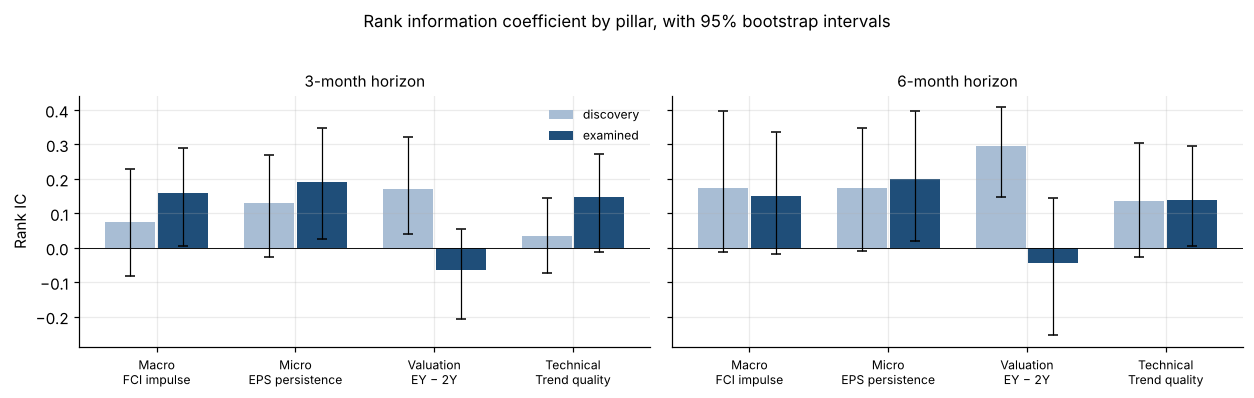

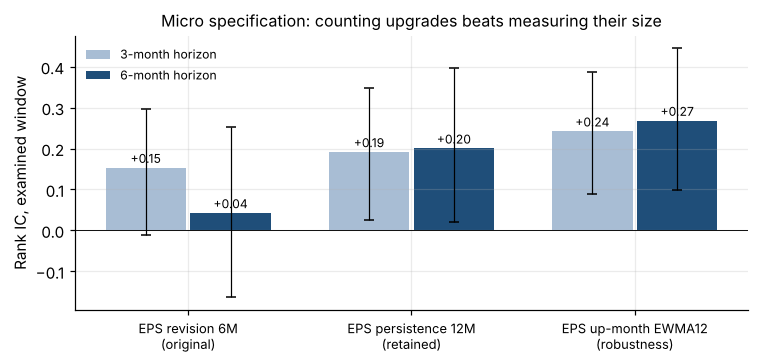

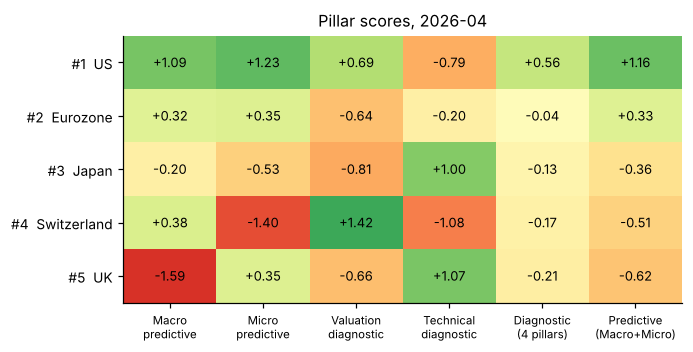

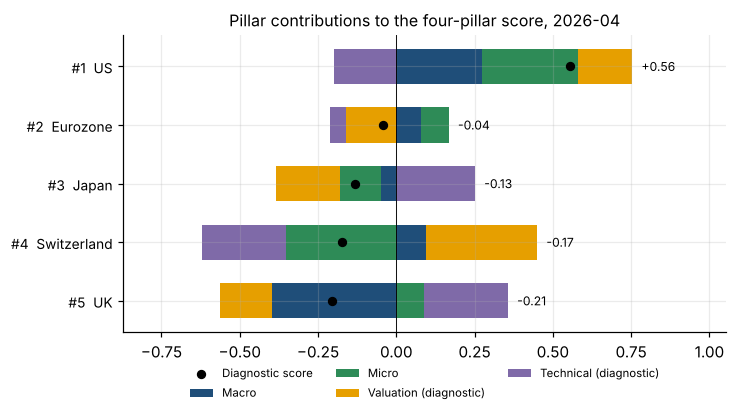

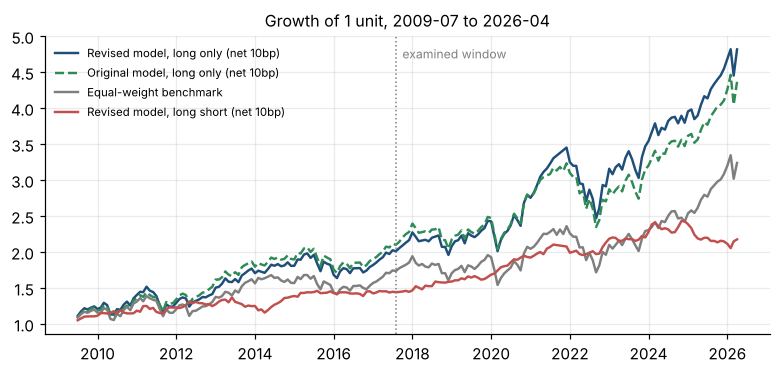

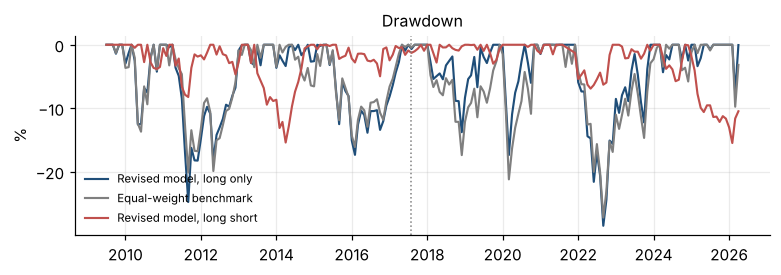

Charts written to output/final/charts


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5), sharey=True)
for ax, h in zip(axes, (3, 6)):
    x = np.arange(4)
    for offset, window, colour in ((-0.19, 'discovery', '#a8bdd4'), (0.19, 'examined', '#1f4e79')):
        values = [PREDICTIVE_POWER.loc[(p, f'{h}M', window), 'IC'] for p in PILLARS]
        low = [PREDICTIVE_POWER.loc[(p, f'{h}M', window), 'CI_low'] for p in PILLARS]
        high = [PREDICTIVE_POWER.loc[(p, f'{h}M', window), 'CI_high'] for p in PILLARS]
        ax.bar(x + offset, values, 0.36, color=colour, label=window,
               yerr=[np.array(values) - low, np.array(high) - values], capsize=3, error_kw={'lw': 0.8})
    ax.axhline(0, color='black', lw=0.6); ax.set_xticks(x)
    ax.set_xticklabels(['Macro\nFCI impulse', 'Micro\nEPS persistence', 'Valuation\nEY − 2Y', 'Technical\nTrend quality'], fontsize=8)
    ax.set_title(f'{h}-month horizon', fontsize=10)
axes[0].set_ylabel('Rank IC'); axes[0].legend(fontsize=8, frameon=False)
fig.suptitle('Rank information coefficient by pillar, with 95% bootstrap intervals', fontsize=11, y=1.02)
plt.tight_layout(); plt.savefig(CH / 'ic_by_pillar.png', dpi=220, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(7.0, 3.4))
labels = ['EPS revision 6M\n(original)', 'EPS persistence 12M\n(retained)', 'EPS up-month EWMA12\n(robustness)']
keys = ['EPS revision 6M only', 'EPS positive-month share 12M', 'EPS up-month EWMA12']
x = np.arange(3)
for offset, h, colour in ((-0.19, 3, '#a8bdd4'), (0.19, 6, '#1f4e79')):
    values = [MICRO_MATCHED.loc[(h, 'USD', k), 'IC'] for k in keys]
    low = [MICRO_MATCHED.loc[(h, 'USD', k), 'CI_low'] for k in keys]
    high = [MICRO_MATCHED.loc[(h, 'USD', k), 'CI_high'] for k in keys]
    ax.bar(x + offset, values, 0.36, color=colour, label=f'{h}-month horizon',
           yerr=[np.array(values) - low, np.array(high) - values], capsize=3, error_kw={'lw': 0.8})
    for xi, v in zip(x + offset, values): ax.text(xi, v + 0.012, f'{v:+.2f}', ha='center', fontsize=8)
ax.axhline(0, color='black', lw=0.6); ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel('Rank IC, examined window'); ax.legend(fontsize=8, frameon=False)
ax.set_title('Micro specification: counting upgrades beats measuring their size', fontsize=10.5)
plt.tight_layout(); plt.savefig(CH / 'micro_comparison.png', dpi=220, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 3.3))
matrix = CURRENT[[f'{p} score' for p in PILLARS] + ['Diagnostic score', 'Predictive score']]
im = ax.imshow(matrix.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
column_labels = [f'{p}\n{"predictive" if p in PREDICTIVE_PILLARS else "diagnostic"}' for p in PILLARS] + ['Diagnostic\n(4 pillars)', 'Predictive\n(Macro+Micro)']
ax.set_xticks(range(6)); ax.set_xticklabels(column_labels, fontsize=7.5)
ax.set_yticks(range(5)); ax.set_yticklabels([f'#{int(CURRENT.loc[m, "Predictive rank"])}  {m}' for m in CURRENT.index], fontsize=9)
for i in range(5):
    for j in range(6):
        ax.text(j, i, f'{matrix.values[i, j]:+.2f}', ha='center', va='center', fontsize=8.5)
ax.set_title(f'Pillar scores, {AS_OF}', fontsize=10.5); ax.grid(False)
plt.tight_layout(); plt.savefig(CH / 'pillar_heatmap.png', dpi=220, bbox_inches='tight'); plt.show()

order = CURRENT.index[::-1]; positive = np.zeros(5); negative = np.zeros(5)
fig, ax = plt.subplots(figsize=(6.8, 3.9))
for p in PILLARS:
    values = CURRENT.loc[order, f'{p} contribution'].values
    label = p if p in PREDICTIVE_PILLARS else f'{p} (diagnostic)'
    ax.barh(np.arange(5), np.where(values > 0, values, 0), left=positive, color=PILLAR_COLOUR[p], label=label, height=0.6)
    ax.barh(np.arange(5), np.where(values < 0, values, 0), left=negative, color=PILLAR_COLOUR[p], height=0.6)
    positive += np.where(values > 0, values, 0); negative += np.where(values < 0, values, 0)
ax.scatter(CURRENT.loc[order, 'Diagnostic score'], np.arange(5), color='black', zorder=5, s=26, label='Diagnostic score')
for i, m in enumerate(order):
    ax.text(max(positive[i], 0) + 0.03, i, f'{CURRENT.loc[m, "Diagnostic score"]:+.2f}', va='center', fontsize=8)
ax.set_yticks(np.arange(5)); ax.set_yticklabels([f'#{int(CURRENT.loc[m, "Predictive rank"])}  {m}' for m in order], fontsize=9)
ax.axvline(0, color='black', lw=0.6); ax.set_xlim(negative.min() - 0.25, positive.max() + 0.3)
ax.set_title(f'Pillar contributions to the four-pillar score, {AS_OF}', fontsize=10.5)
ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(CH / 'pillar_contributions.png', dpi=220, bbox_inches='tight'); plt.show()

growth = lambda s: (1 + s.loc[BACKTEST_START:].dropna()).cumprod()
series_for_chart = {
    'Revised model, long only (net 10bp)': (BACKTESTS[('Revised: FCI + EPS persistence', 'long_only')][0] - BACKTESTS[('Revised: FCI + EPS persistence', 'long_only')][1] * 1e-3, '#1f4e79', '-'),
    'Original model, long only (net 10bp)': (BACKTESTS[('Original: FCI + EPS revision 6M', 'long_only')][0] - BACKTESTS[('Original: FCI + EPS revision 6M', 'long_only')][1] * 1e-3, '#2e8b57', '--'),
    'Equal-weight benchmark': (BENCHMARK, '#7f7f7f', '-'),
    'Revised model, long short (net 10bp)': (BACKTESTS[('Revised: FCI + EPS persistence', 'long_short')][0] - BACKTESTS[('Revised: FCI + EPS persistence', 'long_short')][1] * 1e-3, '#c0504d', '-'),
}
fig, ax = plt.subplots(figsize=(7.2, 3.5))
for label, (s, colour, style) in series_for_chart.items():
    c = growth(s); ax.plot(c.index.to_timestamp(), c.values, style, color=colour, label=label, lw=1.6)
ax.axvline(pd.Timestamp('2017-07-31'), color='grey', ls=':', lw=1)
ax.text(pd.Timestamp('2017-09-30'), ax.get_ylim()[1] * 0.97, 'examined window', fontsize=8, va='top', color='grey')
ax.set_title(f'Growth of 1 unit, {BACKTEST_START} to {AS_OF}', fontsize=10.5); ax.legend(fontsize=7.5, loc='upper left', frameon=False)
plt.tight_layout(); plt.savefig(CH / 'cumulative_vs_benchmark.png', dpi=220, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 2.6))
for label, (s, colour, style) in list(series_for_chart.items())[:1] + list(series_for_chart.items())[2:]:
    c = growth(s); ax.plot(c.index.to_timestamp(), (c / c.cummax() - 1).values * 100, style, color=colour, label=label.split(' (')[0], lw=1.4)
ax.axvline(pd.Timestamp('2017-07-31'), color='grey', ls=':', lw=1)
ax.set_ylabel('%'); ax.set_title('Drawdown', fontsize=10.5); ax.legend(fontsize=7.5, loc='lower left', frameon=False)
plt.tight_layout(); plt.savefig(CH / 'drawdown.png', dpi=220, bbox_inches='tight'); plt.show()
print('Charts written to', CH.relative_to(ROOT))

## 13. Conclusions and limitations

### What the research established
1. **The financial-conditions impulse is the most dependable macro input.** It is positive in both windows at both horizons, stays positive with any single market removed, and retains about half of its six-month information coefficient once the other pillars are stripped out. No activity, credit or rate alternative beat it.
2. **Counting earnings upgrades works better than measuring their size.** Replacing the six-month EPS revision with the twelve-month share of positive revision months raises the examined-window information coefficient at the six-month horizon from about +0.04 to about +0.20 on identical months. The original specification was dominated by occasional large revisions; the persistence measure is not.
3. **The simple equal-weight combination of the two is the best model tested.** It beats the original combination at both horizons and beats the Ridge regression, which had access to all four pillars and still did worse out of sample.
4. **Valuation and Technical do not earn predictive weight.** Both are reported on the scorecard because the framework calls for four pillars, and both are labelled so that nobody reads more into them than the evidence supports.

### What the research did not establish
No pillar is statistically significant once the length of the research process is taken into account. The examined window has been looked at many times and is not a clean holdout. The honest description of the result is an improved and more stable historical relationship that justifies running the model forward, not a proven edge.

### Limitations
| Limitation | Consequence |
|---|---|
| The dataset contains no index prices; the index is reconstructed from forward P/E × forward EPS | Validated against a published index for one market only. The Technical pillar is arithmetically a function of Valuation and Micro inputs |
| Returns are price returns | Higher-yielding markets are understated. No dividend data is supplied |
| The point-in-time status of consensus EPS cannot be verified | The one-month implementation lag is used throughout to limit the exposure to this |
| The US uses a different EPS field from the other four markets, and it is smoother | Cross-market comparability of the Micro pillar is imperfect |
| Switzerland uses the euro-area financial-conditions and credit series | Its macro reading is not Swiss-specific |
| Five markets and roughly 17 independent six-month periods in the examined window | Confidence intervals are wide and country concentration matters |
| The panel ends 30 April 2026 | The ranking is the latest the data supports, not a current market view |

### What I would do next
Run the model forward on new months without refitting, and track the information coefficient of the frozen specification. Obtain total-return indices and a point-in-time consensus history, both of which would remove two of the limitations above rather than work around them. Widen the cross-section, since five markets is the binding constraint on how much any ranking signal can deliver.

In [21]:
summary_rows = []
for p in PILLARS:
    summary_rows.append({'pillar': p, 'indicator': SIGNAL_SPEC.loc[p, 'indicator'], 'label': CONFIDENCE.loc[p, 'label'],
                         'IC_examined_3M': PREDICTIVE_POWER.loc[(p, '3M', 'examined'), 'IC'],
                         'IC_examined_6M': PREDICTIVE_POWER.loc[(p, '6M', 'examined'), 'IC'],
                         'min_leave_one_out_6M': ROBUSTNESS_SUMMARY.loc[(p, '6M'), 'min_leave_one_out'],
                         'weight_in_diagnostic_score': 0.25,
                         'weight_in_predictive_score': round(1 / len(PREDICTIVE_PILLARS), 2) if p in PREDICTIVE_PILLARS else 0.0})
FINAL_SUMMARY = pd.DataFrame(summary_rows).set_index('pillar')
display(FINAL_SUMMARY.round(3))
FINAL_SUMMARY.to_csv(OUT / 'final_pillar_summary.csv')

FIGURES['model_comparison'] = {name: {'IC_examined_3M': float(MODEL_COMPARISON.loc[name, 'IC_examined_3M']),
                                      'IC_examined_6M': float(MODEL_COMPARISON.loc[name, 'IC_examined_6M']),
                                      'long_only_sharpe': float(MODEL_COMPARISON.loc[name, 'long_only_sharpe_full']),
                                      'long_only_IR': float(MODEL_COMPARISON.loc[name, 'long_only_IR_full']),
                                      'long_short_sharpe_full': float(MODEL_COMPARISON.loc[name, 'long_short_sharpe_full']),
                                      'long_short_sharpe_examined': float(MODEL_COMPARISON.loc[name, 'long_short_sharpe_examined']),
                                      'max_drawdown': float(MODEL_COMPARISON.loc[name, 'long_short_max_drawdown_pct']),
                                      'turnover': float(MODEL_COMPARISON.loc[name, 'turnover_pa'])} for name in MODELS}
FIGURES['backtest'] = {}
for window in WINDOWS:
    for model, book, tag in [('Revised: FCI + EPS persistence', 'long_only', 'revised_LO'),
                             ('Revised: FCI + EPS persistence', 'long_short', 'revised_LS'),
                             ('Original: FCI + EPS revision 6M', 'long_only', 'original_LO'),
                             ('Diagnostic scorecard (four pillars)', 'long_only', 'diagnostic_LO')]:
        for metric in ('return_pct_pa', 'volatility_pct_pa', 'sharpe', 'max_drawdown_pct', 'turnover_pa'):
            FIGURES['backtest'][f'{window}_{tag}_{metric}'] = float(BACKTEST_SUMMARY.loc[(window, model, book, 10), metric])
        if book == 'long_only':
            FIGURES['backtest'][f'{window}_{tag}_information_ratio'] = float(BACKTEST_SUMMARY.loc[(window, model, book, 10), 'information_ratio'])
    for metric in ('return_pct_pa', 'volatility_pct_pa', 'sharpe', 'max_drawdown_pct'):
        FIGURES['backtest'][f'{window}_benchmark_{metric}'] = float(BACKTEST_SUMMARY.loc[(window, 'Equal-weight benchmark', 'long_only', 0), metric])
FIGURES['cost_sensitivity'] = {str(c): float(COST_SENSITIVITY.loc[('Revised: FCI + EPS persistence', 'long_short', c), 'sharpe']) for c in (0, 5, 10, 20)}
FIGURES['backtest_window'] = {w: f'{a} to {b}' for w, (a, b) in WINDOWS.items()}
FIGURES['micro_matched_months_3M'] = int(MICRO_MATCHED.xs((3, 'USD')).loc['EPS revision 6M only', 'months'])
FIGURES['micro_old_3M'] = float(MICRO_MATCHED.xs((3, 'USD')).loc['EPS revision 6M only', 'IC'])
FIGURES['micro_new_3M'] = float(MICRO_MATCHED.xs((3, 'USD')).loc['EPS positive-month share 12M', 'IC'])
FIGURES['signal_lag_months'] = SIGNAL_LAG
with open(OUT / 'presentation_figures.json', 'w') as f:
    json.dump(FIGURES, f, indent=2, default=float)

generated = sorted(p.name for p in OUT.glob('*.csv'))
print(f'{len(generated)} CSV files written to {OUT.relative_to(ROOT)}:')
for name in generated: print('   ', name)
print(f'\n{len(list(CH.glob("*.png")))} charts written to {CH.relative_to(ROOT)}.')
print(f'\nHeadline result: the revised model scores an examined-window rank IC of '
      f"{FIGURES['model_comparison'][PRIMARY_MODEL]['IC_examined_6M']:+.3f} at six months against "
      f"{FIGURES['model_comparison']['Original: FCI + EPS revision 6M']['IC_examined_6M']:+.3f} for the original.")

,indicator,label,IC_examined_3M,IC_examined_6M,min_leave_one_out_6M,weight_in_diagnostic_score,weight_in_predictive_score
pillar,,,,,,,
Macro,"Financial conditions impulse, 6 months",PREDICTIVE (provisional),0.158,0.150,0.101,0.250,0.500
Micro,"Earnings revision persistence, 12 months",PREDICTIVE (provisional),0.191,0.200,0.109,0.250,0.500
Valuation,Earnings yield spread versus own history,DIAGNOSTIC,-0.063,-0.044,0.077,0.250,0.000
Technical,"Signed trend quality, 12 months",DIAGNOSTIC,0.149,0.140,-0.003,0.250,0.000


37 CSV files written to output/final:
    aggregate_country_scores.csv
    backtest_performance_summary.csv
    benchmark_returns.csv
    clean_monthly_panel.csv
    country_attribution.csv
    country_ic_contributions.csv
    country_rankings.csv
    current_ranking.csv
    data_dictionary.csv
    data_quality_findings.csv
    final_pillar_summary.csv
    macro_research_comparison.csv
    macro_signal_history.csv
    micro_second_order_test.csv
    micro_signal_history.csv
    micro_walk_forward.csv
    model_comparison.csv
    monthly_portfolio_returns.csv
    pillar_scores.csv
    predictive_power.csv
    recent_predictive_ranks.csv
    robustness_summary.csv
    scorecard_history.csv
    scorecard_ic.csv
    signal_classification.csv
    signal_comparison.csv
    signal_definitions.csv
    signal_inputs.csv
    technical_alternatives.csv
    technical_diagnostic.csv
    technical_signal_history.csv
    technical_walk_forward.csv
    timing_sensitivity.csv
    transaction_cost_sensi